# <span style="color:green"> Numerical Simulation Laboratory </span>
## <span style="color:brown"> Python Exercise 11 </span>
## <span style="color:orange"> Keras - Neural Network regression </span>

### Overview 

In this notebook our task will be to perform machine learning regression on noisy data with a Neural Network (NN).

We will explore how the ability to fit depends on the structure of the NN. The goal is also to build intuition about why prediction is difficult.

### The Prediction Problem

Consider a probabilistic process that gives rise to labeled data $(x,y)$. The data is generated by drawing samples from the equation

$$
    y_i= f(x_i) + \eta_i,
$$

where $f(x_i)$ is some fixed, but (possibly unknown) function, and $\eta_i$ is a Gaussian, uncorrelate noise variable such that

$$
\langle \eta_i \rangle=0 \\
\langle \eta_i \eta_j \rangle = \delta_{ij} \sigma
$$

We will refer to the $f(x_i)$ as the **true features** used to generate the data. 

To make predictions, we will consider a NN that depends on its parameters, weights and biases. The functions that the NN can model respresent the **model class** that we are using to try to model the data and make predictions.

To learn the parameters of the NN, we will train our models on a **training data set** and then test the effectiveness of the NN on a *different* dataset, the **validation data set**. The reason we must divide our data into a training and test dataset is that the point of machine learning is to make accurate predictions about new data we have not seen.

To measure our ability to predict, we will learn our parameters by fitting our training dataset and then making predictions on our test data set. One common measure of predictive  performance of our algorithm is to compare the predictions,$\{y_j^\mathrm{pred}\}$, to the true values $\{y_j\}$. A commonly employed measure for this is the sum of the mean square-error (MSE) on the test set:
$$
MSE= \frac{1}{N_\mathrm{test}}\sum_{j=1}^{N_\mathrm{test}} (y_j^\mathrm{pred}-y_j)^2
$$

We will try to get a qualitative picture by examining plots on validation and training data.

### Linear fit

We start by considering the very simple case:
$$
f(x)=2x+1
$$

Let's start defining the parameters of an ideal linear function which we are going to predict through a neural network regression

In [1]:
# target parameters of f(x) = m*x + b
m = 2 # slope
b = 1 # intersect

Now let's generate a set of input data which will slightly deviate from our ideal behaviour using a random noise (that actually is set to zero):

In [2]:
import numpy as np

# generate training inputs
np.random.seed(0)
x_train = np.random.uniform(-1, 1, 500)
x_valid = np.random.uniform(-1, 1, 50)
x_valid.sort()
y_target = m * x_valid + b # ideal (target) linear function

sigma = 0.2 # noise standard deviation, for the moment it is absent
y_train = np.random.normal(m * x_train + b, sigma) # actual measures from which we want to guess regression parameters
y_valid = np.random.normal(m * x_valid + b, sigma)

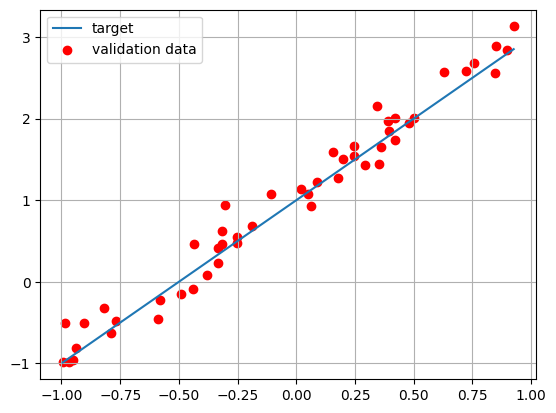

In [3]:
# plot validation and target dataset
import matplotlib.pyplot as plt
plt.plot(x_valid, y_target, label='target')
plt.scatter(x_valid, y_valid, color='r', label='validation data')
plt.legend()
plt.grid(True)
plt.show()

If you remember how a single node of a neural network works, you can easily spot that **just a single neuron can make the job**. So let's start using a simple Sequential model with just one layer on one neuron only!

In [4]:
# compose the NN model
import tensorflow as tf
from tensorflow import keras

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras import backend as K
from tensorflow.keras.utils import get_custom_objects

model = tf.keras.Sequential()
model.add(Input(shape=(1,)))
model.add(Dense(1))

# compile the model choosing optimizer, loss and metrics objects
model.compile(optimizer='sgd', loss='mse', metrics=['mse'])

2026-10-12 17:36:43.698829: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [5]:
# get a summary of our composed model
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 1)              │             2 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2 (8.00 B)

 Trainable params: 2 (8.00 B)

 Non-trainable params: 0 (0.00 B)

We are now going to train our model, that is we feed the neuron with the set of training pair x, y_train from which the optimizer will find the best weights to minimize the Mean Square Error loss function (out linear regression function).

In [6]:
# fit the model using training dataset
# over 10 epochs of 32 batch size each
# report training progress against validation data
history = model.fit(x=x_train, y=y_train, 
          batch_size=32, epochs=30,
          shuffle=True, # a good idea is to shuffle input before at each epoch
          validation_data=(x_valid, y_valid))

Epoch 1/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 3.7009 - mse: 3.7009 - val_loss: 2.8960 - val_mse: 2.8960
Epoch 2/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 2.7890 - mse: 2.7890 - val_loss: 2.2210 - val_mse: 2.2210
Epoch 3/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 2.1533 - mse: 2.1533 - val_loss: 1.7364 - val_mse: 1.7364
Epoch 4/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 1.6907 - mse: 1.6907 - val_loss: 1.3716 - val_mse: 1.3716
Epoch 5/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 1.3391 - mse: 1.3391 - val_loss: 1.0959 - val_mse: 1.0959
Epoch 6/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 1.0727 - mse: 1.0727 - val_loss: 0.8782 - val_mse: 0.8782
Epoch 7/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.8612 - mse: 0.8612 - val_loss: 0.7078 - val_mse: 0.7078
Epoch 8/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.6961 - mse: 0.6961 - val_loss: 0.5742 - val_mse: 0.5742
Epoch 9/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.5655 - mse:

By looking at weights and biases we can see if the linear fit was successfull: $w_1$ represents the angular coefficient, $b$ the intercept.

In [7]:
# return weights and biases
model.get_weights()

[array([[1.9034983]], dtype=float32), array([0.9779164], dtype=float32)]

In [8]:
# evaluate model
score = model.evaluate(x_valid, y_valid, batch_size=32, verbose=1)

# print performance
print()
print('Test loss:', score[0])
print('Test accuracy:', score[1])

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 0.0472 - mse: 0.0472

Test loss: 0.047190967947244644
Test accuracy: 0.047190967947244644


In [9]:
# evaluate model with the exact curve
score = model.evaluate(x_valid, y_target, batch_size=32, verbose=1)

# print performance
print()
print('Test loss:', score[0])
print('Test accuracy:', score[1])

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - loss: 0.0032 - mse: 0.0032

Test loss: 0.0032352127600461245
Test accuracy: 0.0032352127600461245


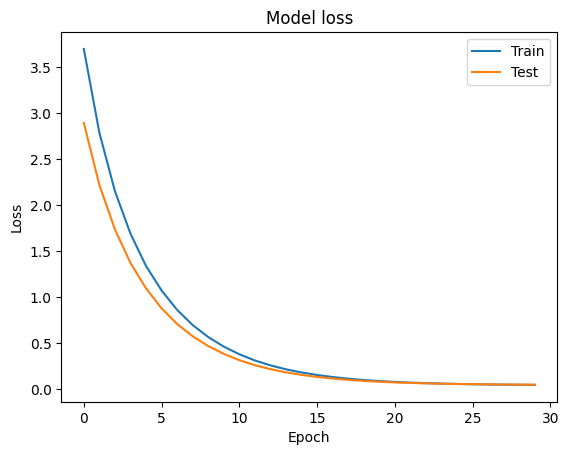

In [10]:
# look into training history
# Plot training & validation loss values
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Test'], loc='best')
plt.show()

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step


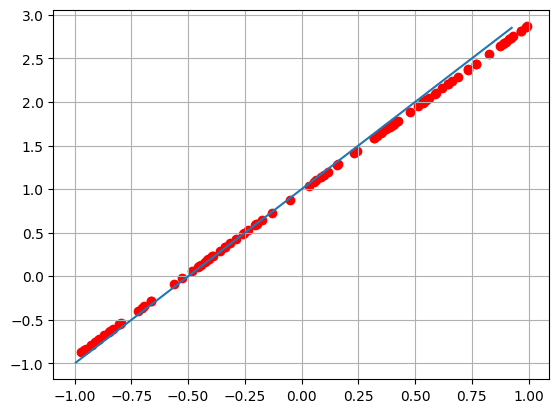

In [11]:
x_predicted = np.random.uniform(-1, 1, 100)
y_predicted = model.predict(x_predicted)
plt.scatter(x_predicted, y_predicted,color='r')
plt.plot(x_valid, y_target)
plt.grid(True)
plt.show()

### Exercise 11.1

In order to make practice with NN, explore how does the previous linear regression depend on the number of epochs, $N_{\mathrm{epochs}}$, the number of data points $N_{\mathrm{train}}$ and on the noise $\sigma$. Try to improve the previous result operating on these parameters.

### <span style="color:green"> RESULTS: </span>

The model is the same as above: a single linear neuron, $y = wx + b$, trained with Stochastic Gradient Descent (SGD), with a learning rate of $0.01$ and minibatches of 32 points, to minimise the MSE. Since the target $f(x)=2x+1$ belongs to this model class, the question here is not which model to use, but how well the training finds the two parameters and how this depends on the following factors:

$N_{\rm epoch}$, the number of passes over the training set. One epoch corresponds to $\lceil N_{\rm train}/32\rceil$ SGD updates, so the total number of updates is $\lceil N_{\rm train}/32\rceil \cdot N_{\rm epoch}$ and this tells us how far the optimization has gone this, not the number of epochs alone.

$N_{\rm train}$, the number of training points. More points carry more information on $w$ and $b$, so the statistical error on the fitted parameters decreases as $\sigma/\sqrt{N_{\rm train}}$.

And finally, $\sigma$, the standard deviation of the Gaussian noise on the data. Since the validation points are noisy too, the validation loss cannot go much below $\sigma^2$, even for a perfect model.

To study these dependences we implemented the function <small><code>run_linear</code></small>, which generates the data, trains the model and draws three plots: the training data with the target line, the training and validation loss as a function of the epochs, and the predictions of the trained model compared with the target. We then varied one parameter at a time, keeping the others fixed, which produced three sets of plots:

$N_{\rm epoch} \in \{10, 207, 405, 602, 800\}$, with $N_{\rm train}=50$ and $\sigma=0.5$;

$N_{\rm train} \in \{10, 132, 255, 377, 500\}$, with $N_{\rm epoch}=50$ and $\sigma=0.5$ (for each the validation set has $0.2\,N_{\rm train}$ points);

$\sigma \in \{0, 0.25, 0.5, 0.75, 1\}$, with $N_{\rm train}=500$ and $N_{\rm epoch}=50$.

The seeds of NumPy and TensorFlow are fixed at the beginning of each run, so that all runs start from the same initial weights and the differences come only from the parameter being varied.

In [12]:
C_BLUE, C_GREEN = "#0c459a", "#109e28"

def run_linear(N_train, N_valid, sigma, N_epoch, title):
    # data
    np.random.seed(0)
    tf.random.set_seed(0)
    x_train = np.random.uniform(-1, 1, N_train)
    x_valid = np.sort(np.random.uniform(-1, 1, N_valid))
    y_train = np.random.normal(m * x_train + b, sigma)
    y_valid = np.random.normal(m * x_valid + b, sigma)

    # model: a single linear neuron
    model = tf.keras.Sequential([Input(shape=(1,)), Dense(1)])
    model.compile(optimizer='sgd', loss='mse', metrics=['mse'])
    history = model.fit(x=x_train, y=y_train, batch_size=32, epochs=N_epoch, shuffle=True, validation_data=(x_valid, y_valid), verbose=0)

    x_predicted = np.sort(np.random.uniform(-1, 1, 100))
    y_predicted = model.predict(x_predicted, verbose=0)
    x_plot = np.linspace(-1, 1, 200)
    y_plot = m * x_plot + b

    # plots:
    fig, axs = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle(title)

    axs[0].scatter(x_train, y_train, color=C_GREEN, alpha=0.5, label='Train')
    axs[0].plot(x_plot, y_plot, color=C_BLUE, label='Target')
    axs[0].set(title='Train data & Target', xlabel='x', ylabel='y')

    axs[1].plot(history.history['loss'], color=C_BLUE, label='Train loss')
    axs[1].plot(history.history['val_loss'], color=C_GREEN, label='Validation loss')
    axs[1].set(title='Loss', xlabel='Epoch', ylabel='MSE')

    axs[2].scatter(x_predicted, y_predicted, color=C_GREEN, label='Predicted')
    axs[2].plot(x_plot, y_plot, color=C_BLUE, label='Target')
    axs[2].set(title='Predictions vs Target', xlabel='x', ylabel='y')

    for ax in axs:
        ax.legend()
        ax.grid(True)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

    return history.history['val_loss']

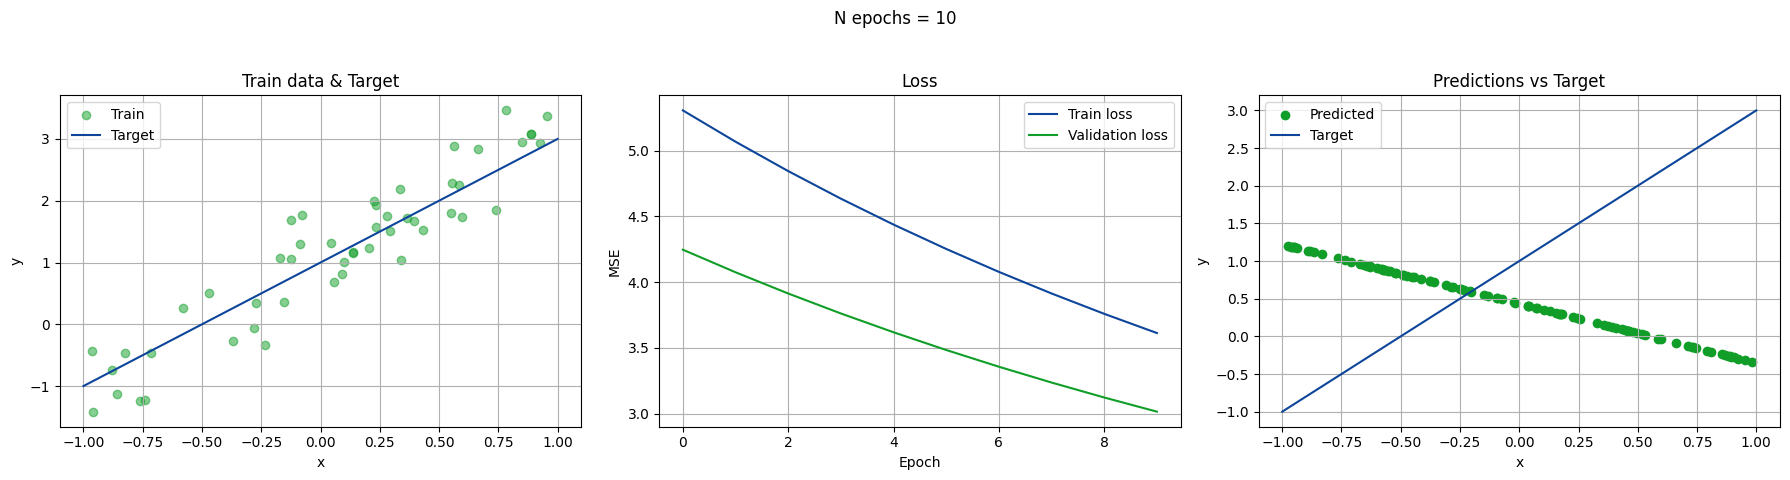

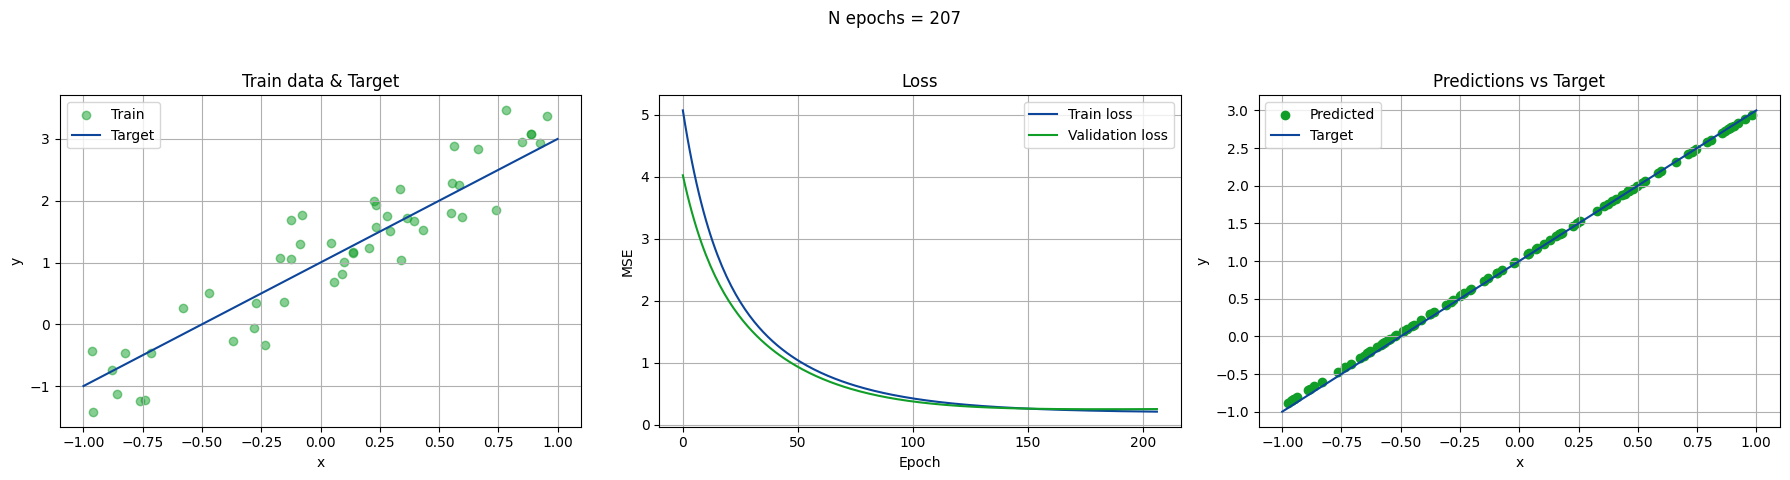

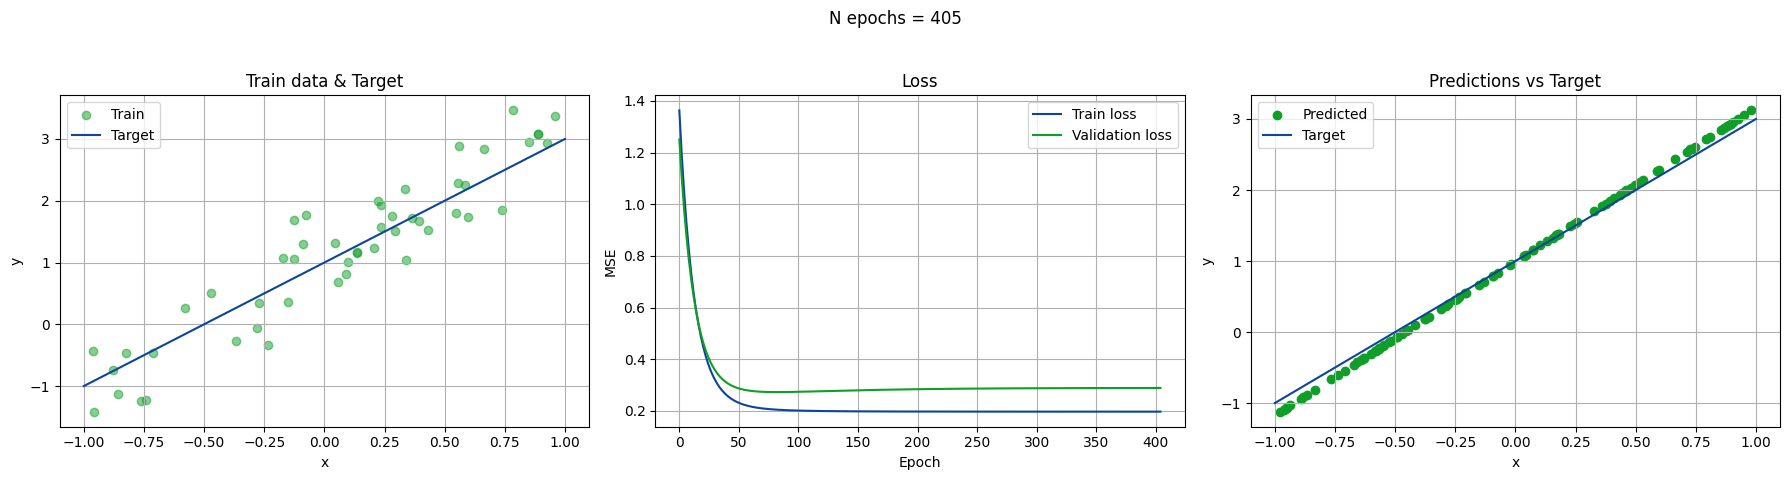

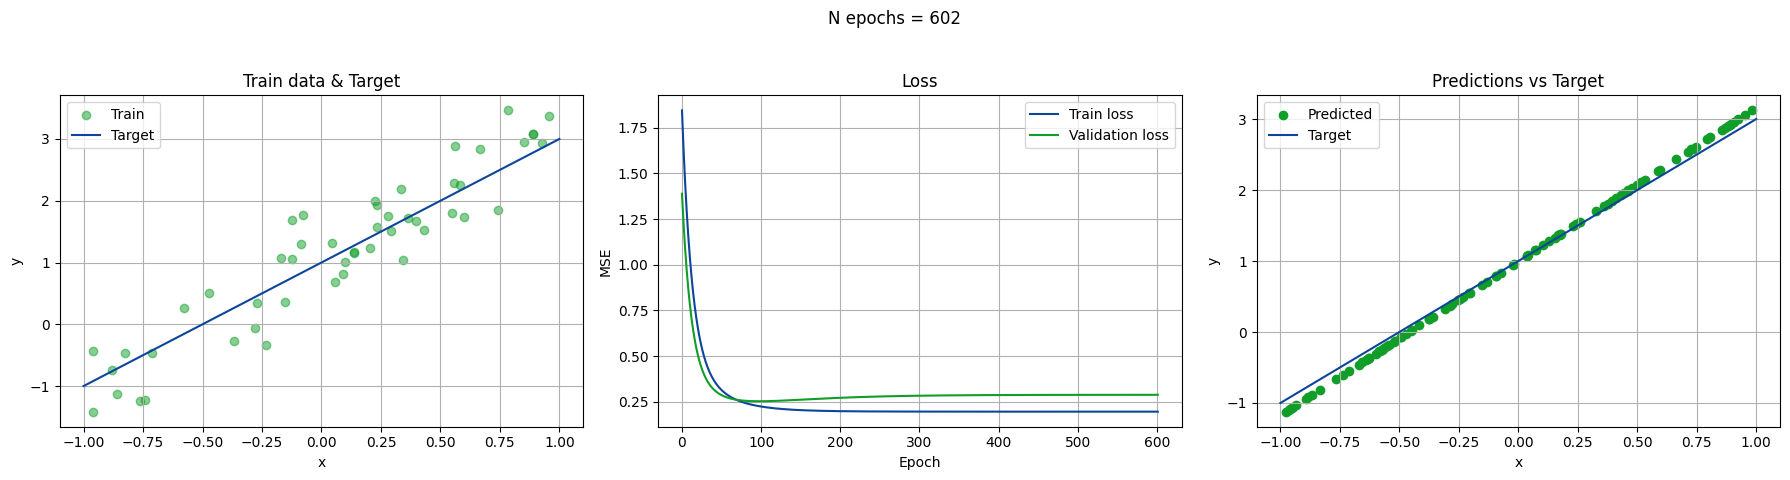

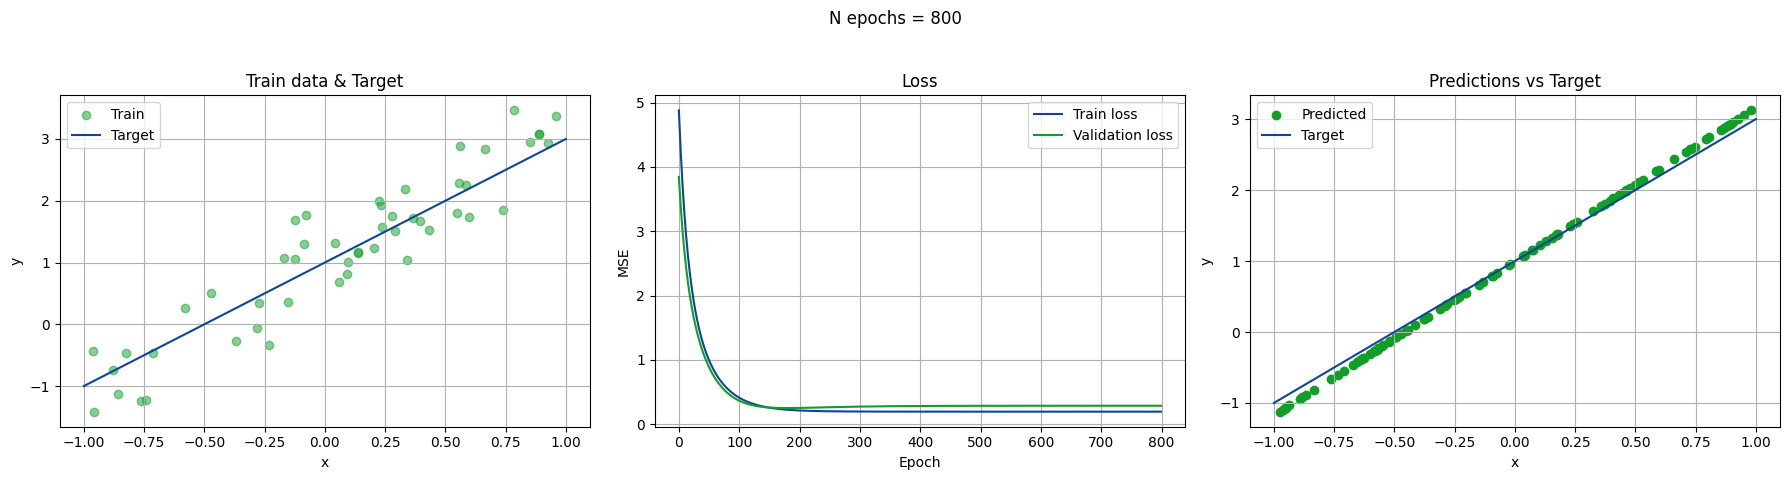

In [13]:
# N_epoch (sigma = 0.5, N_train = 50)
N_epochs = np.linspace(10, 800, 5, dtype=int)
validation_losses_epoch = [run_linear(50, 25, 0.5, N, f"N epochs = {N}") for N in N_epochs]

With $N_{\rm train}=50$ and minibatches of 32 points, one epoch contains only 2 SGD updates. The five runs therefore correspond to 20, 414, 810, 1204 and 1600 updates of the weights.

From the plots we drew the following conclusions: with 10 epochs (20 updates) the training has barely started, the loss is still between 3 and 5 and decreasing steadily, and the predicted line is completely wrong: it even has a negative slope. From this we gathered that the network has not had enough updates to move the weights away from their random initial values. With 207 epochs (414 updates), instead, the loss drops quickly in the first ~50 epochs and reaches a plateau after about 100 epochs, and the predicted line is practically on top of the target. Going further, to 405, 602 and 800 epochs, brings no significant advantage: the loss curves reach the same plateau after about 100-150 epochs, and the extra epochs only add a flat part trough the end. Also the predicted line is the same in the three runs, so once the minimum of the loss has been reached, training longer does not change anything.

There are then two details of the plots that are worth noticing: firstly the plateau is not zero. For the longer simulations we can see how the training and the validation loss settle around $0.25$, which correspond to $\sigma^2 = 0.25$. This is due to the noise in the data: even the exact line $2x+1$ would have an MSE of about $\sigma^2$ on these points.

Another thing we noticed is that the final line is slightly steeper than the target. This could be becouse we only used 50 noisy points to train the model, so it could be that the best line through the training data does not coincide exactly with $2x+1$, and the fitted slope is slighly bigger than $2$. This is a statistical error, of order $\sigma/\sqrt{N_{\rm train}} \approx 0.07$, which does not decrease with more epochs, only with more training data. For the same reason, after the minimum the validation loss rises very slightly: the weights converge to the best line for the 50 training points, which is a little worse for the 25 validation points.

In conclusion, the number of epochs only needs to be large enough for the training to converge, which here happens after about 100 epochs; beyond that, more epochs are useless.

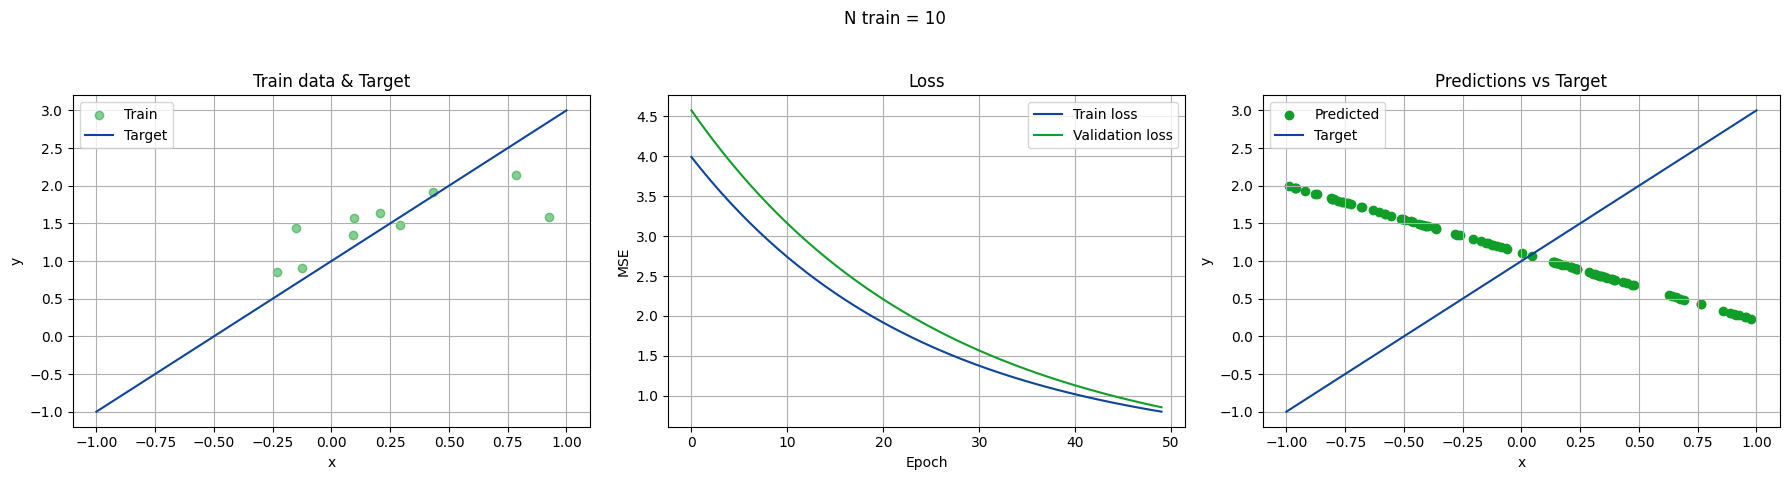

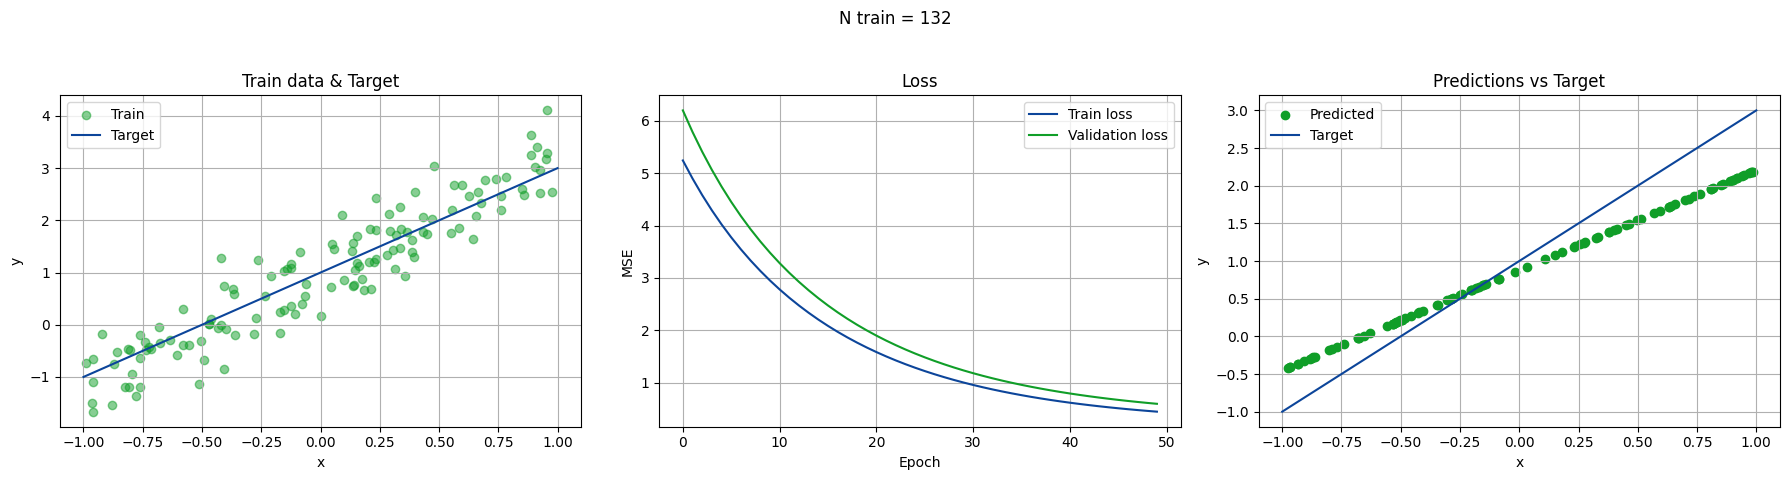

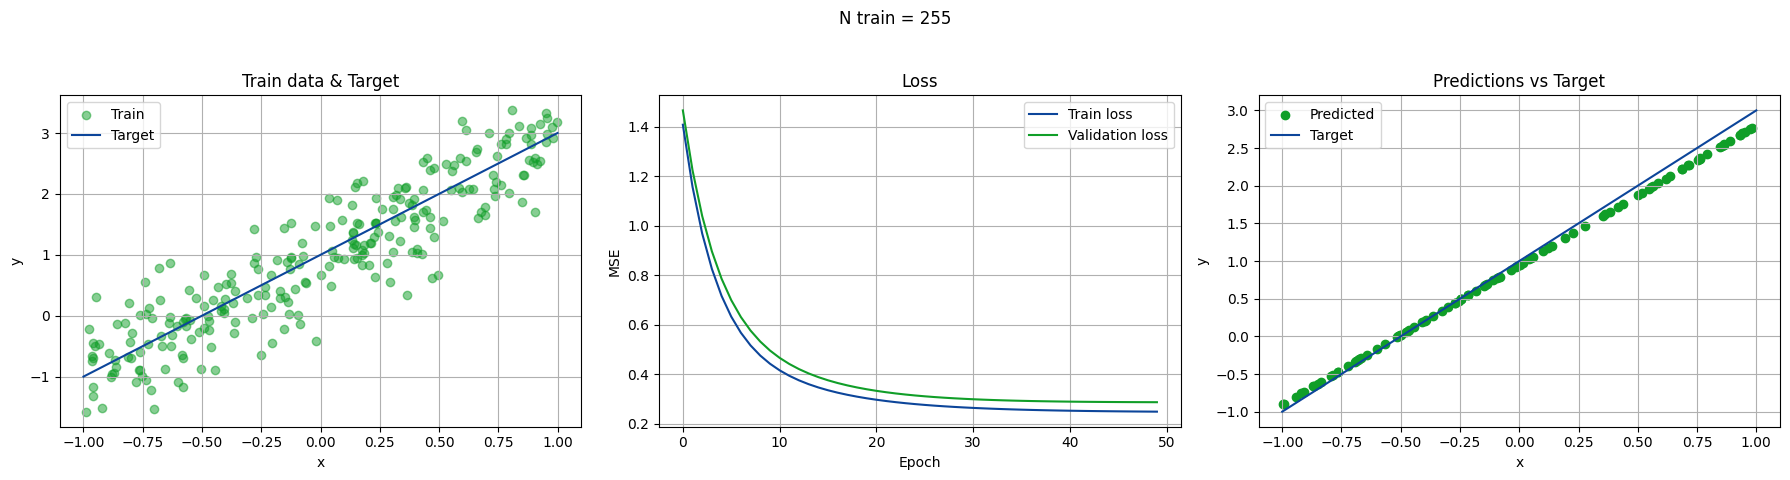

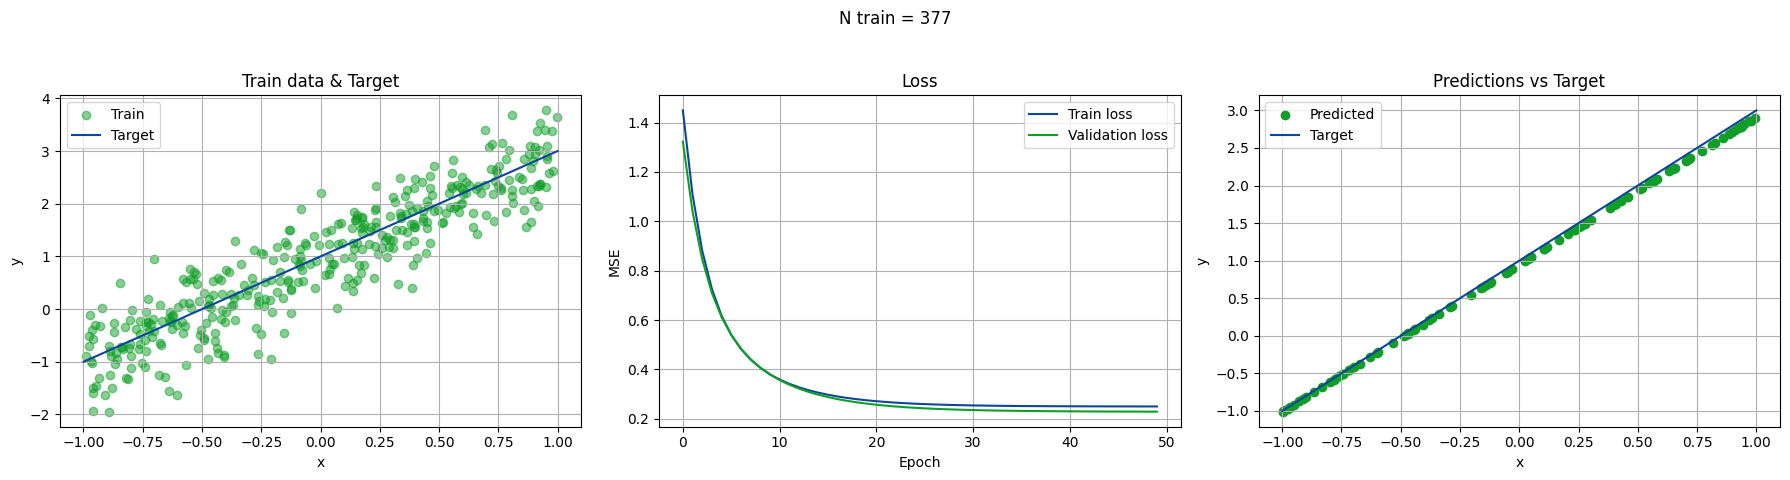

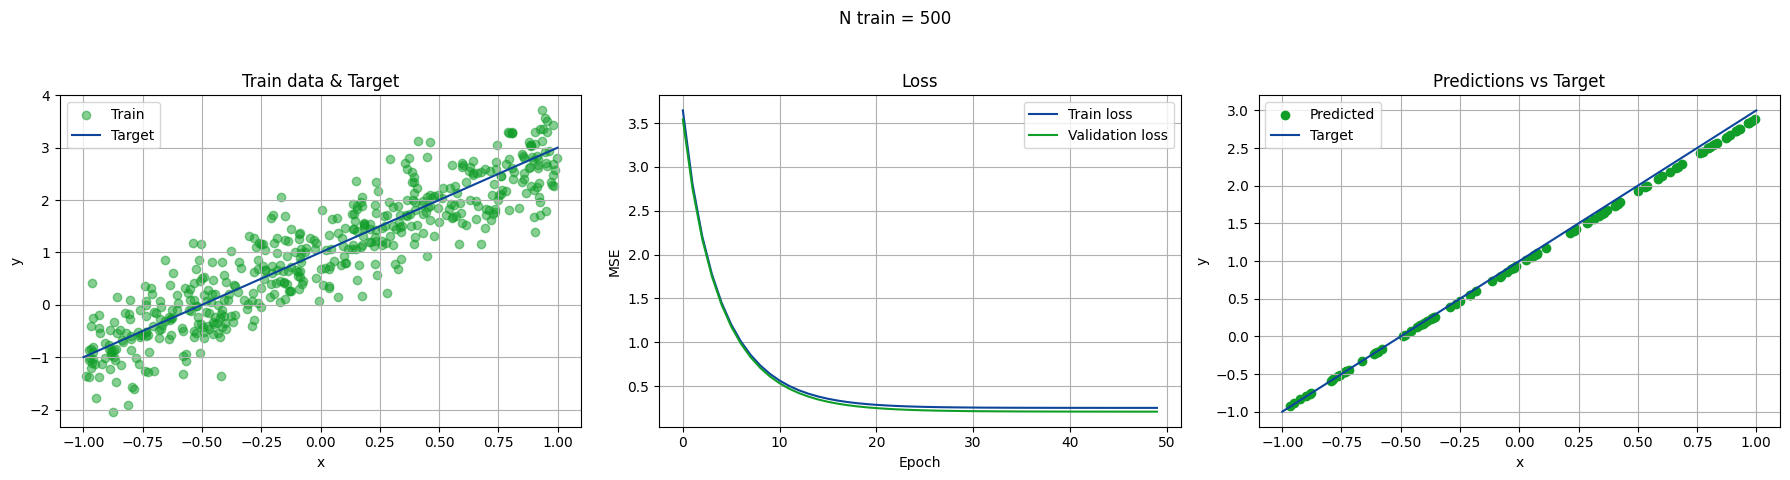

In [ ]:
# N_train (sigma = 0.5, N_epoch = 50)
N_train_values = np.linspace(10, 500, 5, dtype=int)
validation_losses_train = [run_linear(N, int(0.2 * N), 0.5, 50, f"N train = {N}") for N in N_train_values]

Here the number of epochs is fixed at 50, but the number of updates per epoch grows with $N_{\rm train}$, so the five runs correspond to 50, 250, 400, 600 and 800 updates. Increasing $N_{\rm train}$ therefore has two effects at once, firstly more optimisation steps and than more information on the parameters.

From the plots we can draw the following conclusions: with $N_{\rm train}=10$ the fit is poor. In the previous study the loss reached its plateau only after about 200 updates, so 50 updates are not enough for the training to converge. Moreover, with only 10 noisy points the parameters would be poorly determined anyway, and the validation set contains only 2 points, so its loss is not meaningful.

With $N_{\rm train}=132$ and $255$ the training is not complete yet: at epoch 50 both loss curves are still slowly decreasing, and the validation loss is still above $\sigma^2 = 0.25$. Form the predicted lines we can clearly guess which parameter is still missing, they cross the target near $x=0$, so the intercept $b$ is already correct, but they are less steep than the target. FRom this we can suppose that the slope is the slower parameter to learn, and this could be because its gradient is proportional to $x$, which is small for many points of the interval.

With $N_{\rm train}=377$ and $500$ the loss reaches its plateau within the 50 epochs and the predicted line approaches the target even more closely.

As in the previous study, the validation loss saturates around $\sigma^2=0.25$ for all sufficiently large $N_{\rm train}$ so we concluded that more data can improve the parameters, but it cannot reduce the noise in the validation points, which is set by $\sigma$.

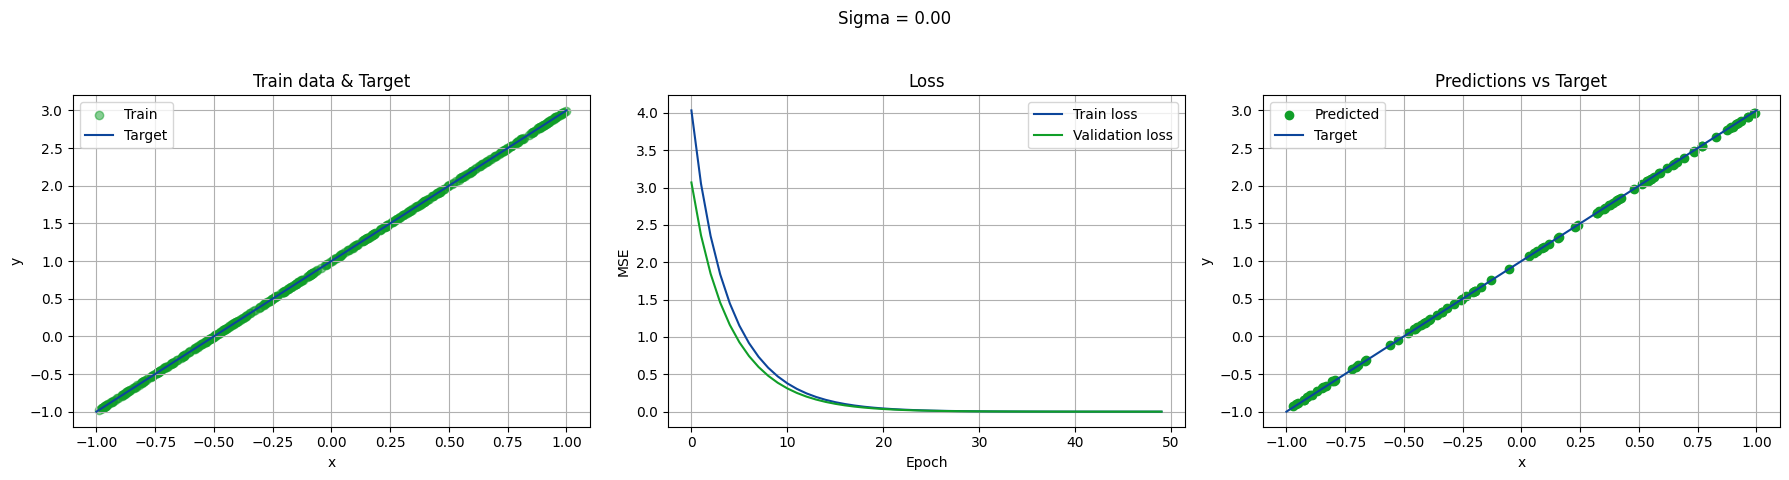

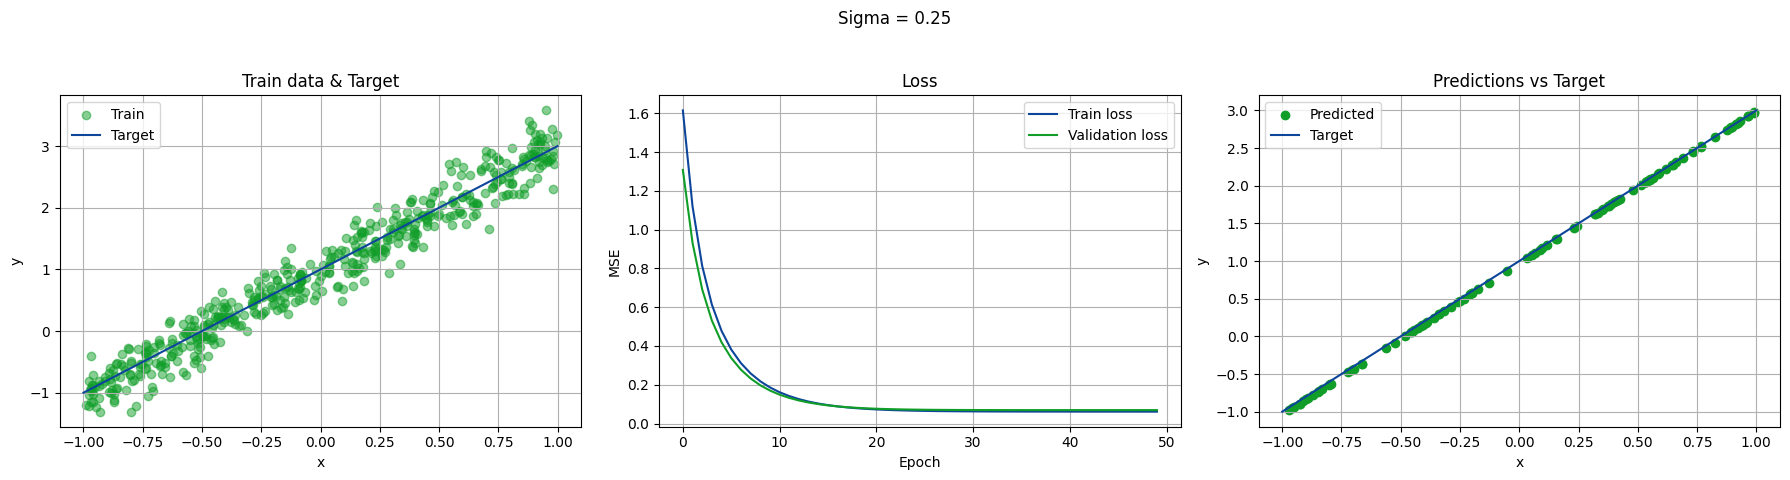

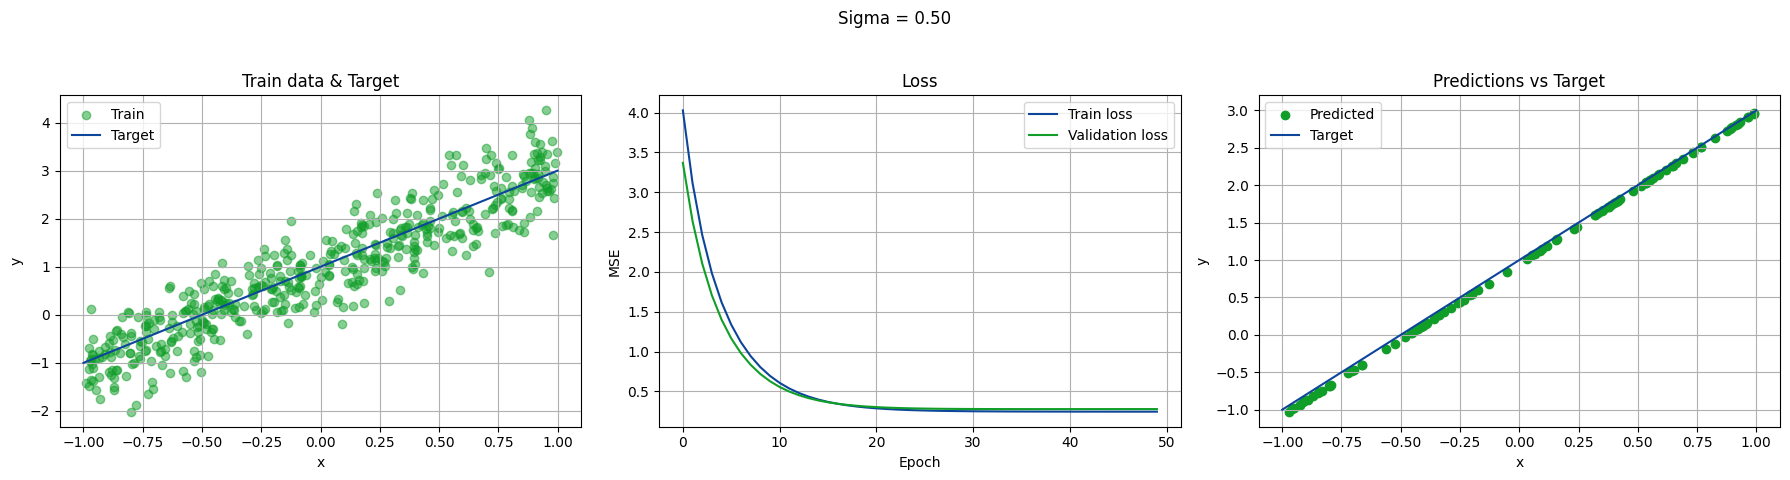

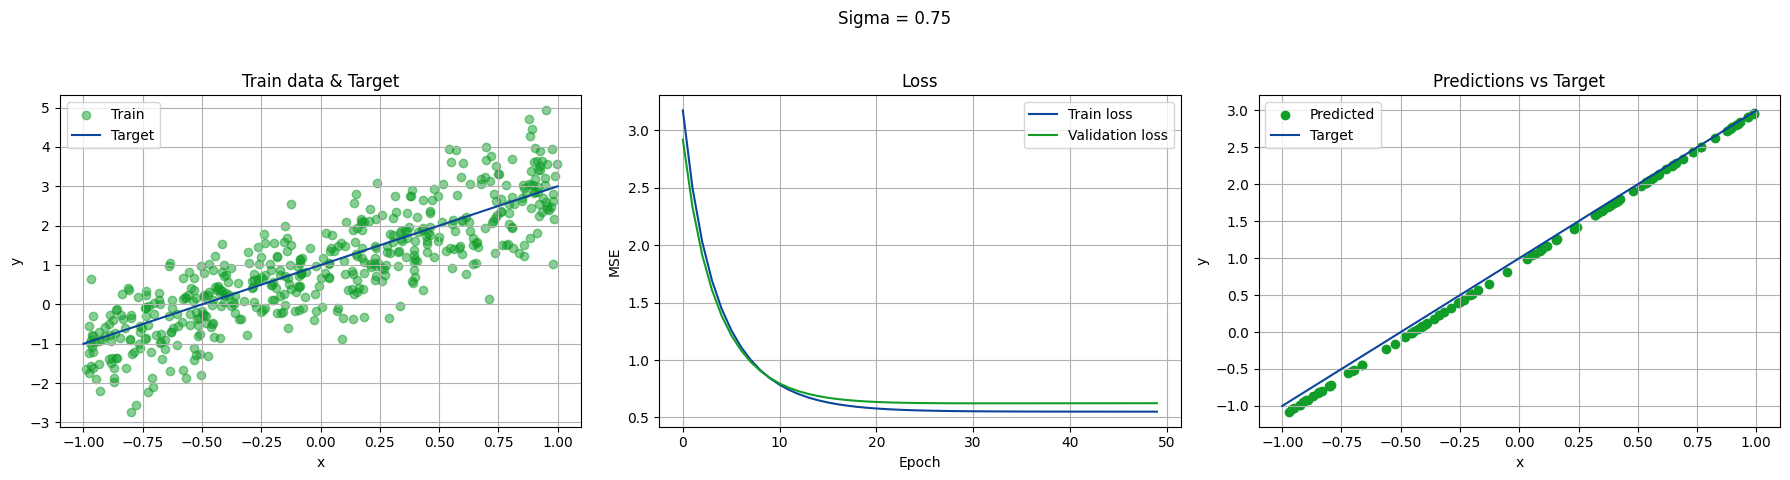

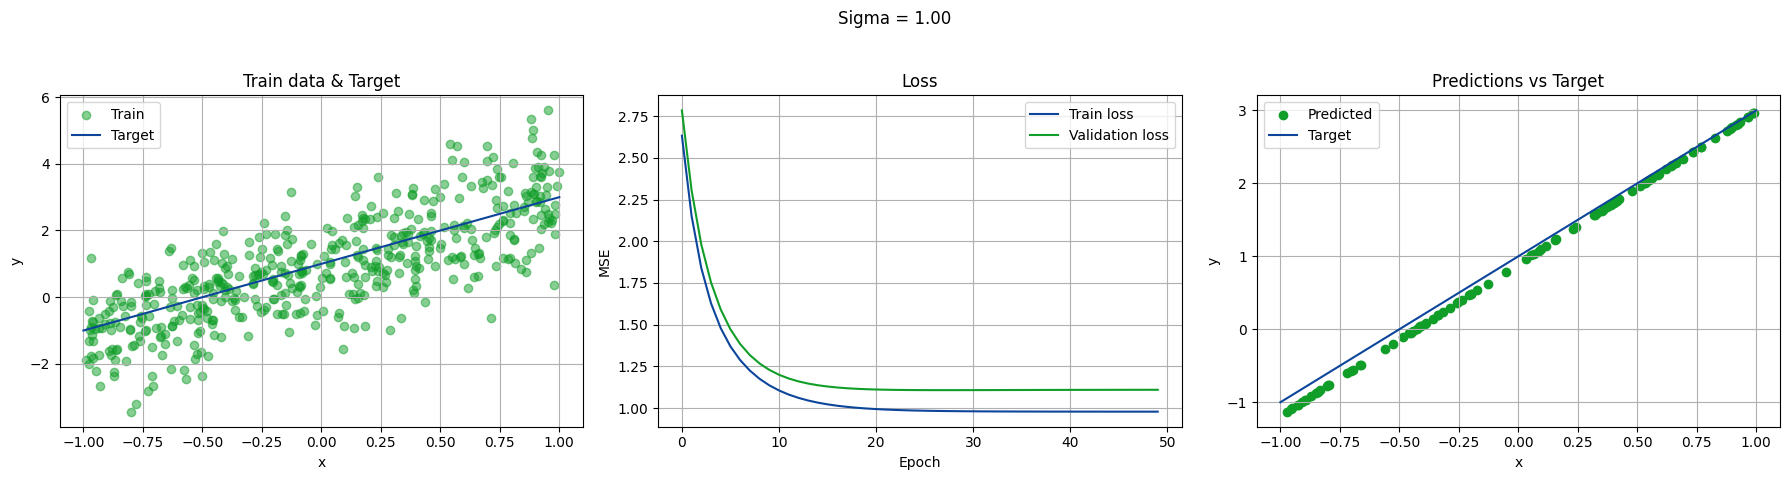

In [15]:
# sigma (N_train = 500, N_epoch = 50)
sigmas = np.linspace(0, 1, 5)
validation_losses_sigma = [run_linear(500, 50, s, 50, f"Sigma = {s:.2f}") for s in sigmas]

To study how the network changed with $\sigma$ we used $N_{\rm train}=500$ and 50 epochs so that the optimisation converges in all five runs, and the differences between the runs would only come from the noise.

From the analysis we found that with $\sigma=0$ the data lie exactly on the line. Training and validation loss go to zero, and the predictions coincide with the target, that was to be aspected as the network trained without noise, so it found exactly $w=2$ and $b=1$.

Increasing $\sigma$, the training data are more and more scattered around the line, and the loss curves reach the plateau at higher values. The plateaus of the training loss remain in good agreement with $\sigma^2$ for each $\sigma$ and the validation losses are slightly higher.

The predicted line, instead, stays close to the target in all runs. Only for the largest values of $\sigma$ a small deviation becomes visible. This is the statistical error on the fitted parameters, which grows with the noise as $\sigma/\sqrt{N_{\rm train}}$ but remains small because 500 points average out most of the noise.

A high loss therefore does not mean a bad model; on noisy data the loss mainly measures the noise, and the quality of the fit must be judged by comparing the predicted line with the target.

#### Comparison of the validation losses

To compare the runs directly, the figure below collects the validation loss as a function of the epoch for all values of each parameter: $\sigma$, $N_{\rm train}$ and $N_{\rm epoch}$. 

To make the curves readable, the first value of each parameter is left out ($\sigma=0$, $N_{\rm train}=10$, $N_{\rm epoch}=10$), because its curve lies on a very different scale. The first epoch is also left out, because there, the loss is still dominated by the random initial weights. And finally in the $N_{\rm epoch}$ panel the horizontal axis is limited to 200 epochs, where the relevant part of the convergence happens.

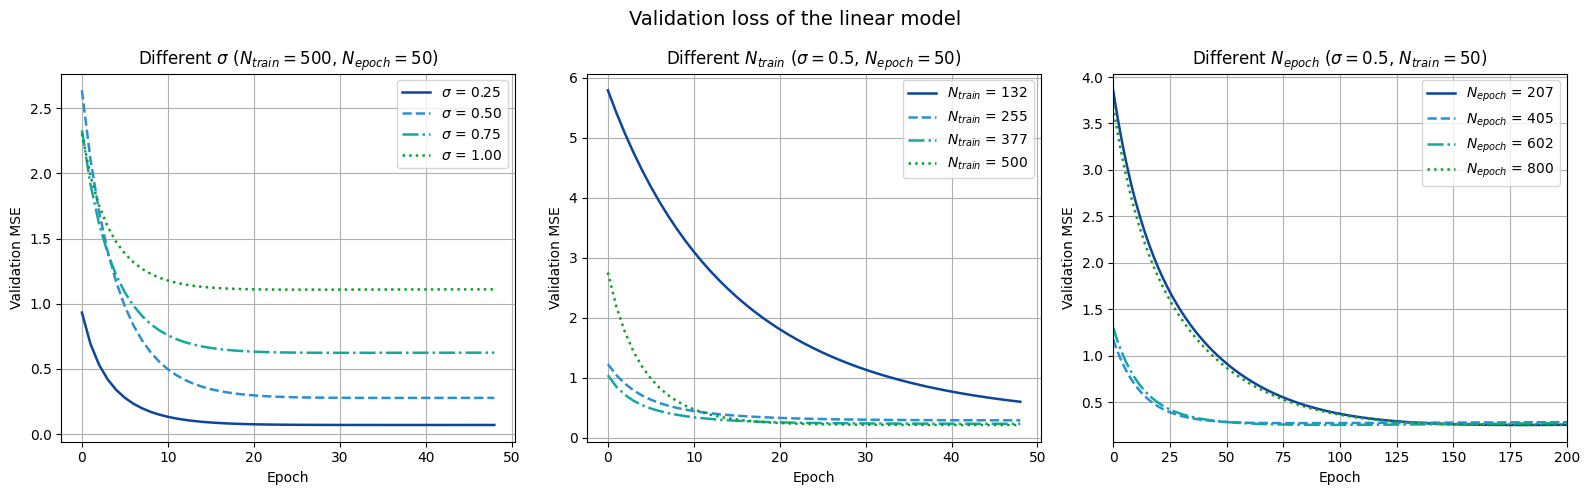

In [16]:
colors = ["#0c459a", "#2b8fd6", "#13a89e", "#109e28"]
styles = ['-', '--', '-.', ':']

panels = [(validation_losses_sigma, sigmas,         r'$\sigma$ = {:.2f}',   r'Different $\sigma$ ($N_{train}=500$, $N_{epoch}=50$)'),
          (validation_losses_train, N_train_values, r'$N_{{train}}$ = {}', r'Different $N_{train}$ ($\sigma = 0.5$, $N_{epoch}=50$)'),
          (validation_losses_epoch, N_epochs,       r'$N_{{epoch}}$ = {}', r'Different $N_{epoch}$ ($\sigma = 0.5$, $N_{train}=50$)')]

fig, axs = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Validation loss of the linear model', fontsize=14)
for ax, (losses, values, label, title) in zip(axs, panels):
    for i in range(1, len(losses)):            # skip the first value of the parameter
        ax.plot(losses[i][1:], color=colors[i - 1], ls=styles[i - 1], lw=1.8, label=label.format(values[i]))
    ax.set(title=title, xlabel='Epoch', ylabel='Validation MSE')
    ax.legend()
    ax.grid(True)
axs[2].set_xlim(0, 200)
plt.tight_layout()
plt.show()

The three panels summarise the role of the three parameters.

On the left, all curves become flat within about 20 epochs, but at very different heights, but all close to their respective $\sigma^2$. From this we gathered that the noise does not change how fast the network learns, it only sets the lowest value that the validation loss can reach.

In the centre, the two largest training sets ($N_{\rm train}=377$, $500$ and $255$) reach the plateau $\approx\sigma^2=0.25$ within about 10 epochs, while for $N_{\rm train}=132$ the loss is still decreasing at epoch 50. With a fixed number of epochs, a larger training set means more updates of the weights, so the training converges in fewer epochs.

On the right, the curves start from different values, because the initial weights are random and different in each run, but they all reach the same plateau, $\approx 0.25$, after about 100-125 epochs. Since the model has a single minimum, the starting point only changes how long it takes to get there, not where the training ends and all the epochs beyond the point where the plateau is reached are useless.

#### Best combination

The noise $\sigma$ is a property of the data and cannot be chosen: it only fixes the floor $\sigma^2$ of the loss. Among the parameters that can be chosen, the best combination is the largest training set, $N_{\rm train}=500$, trained for enough epochs to reach the plateau. With $N_{\rm train}=500$ one epoch contains 16 updates, so about 20-50 epochs are already sufficient. With this combination the error on the parameters is of order $\sigma/\sqrt{N_{\rm train}} \approx 0.02$ for $\sigma=0.5$, so the network finds $w \approx 2$ and $b \approx 1$ with good precision. More data would reduce this error further, while more epochs would not.

### Exercise 11.2

Try to extend the model to obtain a reasonable fit of the following polynomial of order 3:

$$
f(x)=4-3x-2x^2+3x^3
$$
for $x \in [-1,1]$.

Find good (& reasonable) choices for:

- the number of layers
- the number of neurons in each layer
- the activation function
- the optimizer
- the loss function
  
Check your NN model by seeing how well your fits predict newly generated test data (including on data outside the range you fit. How well do your NN do on points in the range of $x$ where you trained the model? How about points outside the original training data set? 
Summarize what you have learned about the relationship between model complexity (number of parameters), goodness of fit on training data, and the ability to predict well.

### <span style="color:green"> RESULTS: </span>

A single linear neuron can only represent a straight line, so to fit the cubic function $f(x) = 4 - 3x - 2x^2 + 3x^3$ the network needs hidden layers with a non-linear activation. To find the best combination of the network parameters, instead of trying a few of them by hand, we explored them systematically with a grid search and trained one network for every combination of:

- number of hidden layers: 1, 2, 3;
- neurons per hidden layer: 8, 16, 32;
- activation function: <small><code>relu</code></small>, <small><code>tanh</code></small>, <small><code>sigmoid</code></small>, <small><code>linear</code></small> (the last one as a reference because without a non-linearity the network can only produce a straight line);
- optimizer: <small><code>adam</code></small>, <small><code>sgd</code></small>, <small><code>rmsprop</code></small>;
- loss function: MSE and MAE,

for a total of $3\cdot3\cdot4\cdot3\cdot2=216$ models. Each model is trained for 50 epochs with mini-batches of 32 points, and its output layer is always a linear <small><code>Dense(1)</code></small>, since the output is a real number.

#### Comparison criterion

The validation loss is not a good criterion to compare the models for two reasons: it has different units for models trained with MSE and with MAE, and, being measured on noisy points, it cannot go below the noise floor $\sigma^2$, so that all good models look the same once the plateau is reached. Since in this exercise the true function is known, we compared the models with the MSE with respect to the exact $f(x)$ on a dense grid:
$$
\mathrm{MSE}_{\rm true} = \frac{1}{N}\sum_i \big(y^{\rm NN}(x_i) - f(x_i)\big)^2 ,
$$
computed both inside the training interval, $|x|\le 1$, and outside it, $1<|x|\le1.5$. This measures directly how well the network has learned the function and how well it extrapolates.

The analysis consists of the following steps:
1. Generate the noisy training and validation data.
2. Train all 216 models and compute their errors.
3. Show the results as a heat map, to see the effect of each choice and of the model complexity.
4. Retrain the 5 best models with 5 different random seeds, to check that their ranking is not due to a lucky initialisation, and choose the simplest model whose error is compatible with the best one.
5. Check the learning curves of the candidates and the predictions of the chosen model on new data, in the interval $[-2,2]$.

In [17]:
import itertools
from tqdm import tqdm

C_BLUE, C_GREEN = "#0c459a", "#109e28"

def cubic_function(x):
    return 4 - 3*x - 2*x**2 + 3*x**3

In [18]:
# parameter space of the grid search
layer_options      = [1, 2, 3]
neurons_options    = [8, 16, 32]
activation_options = ['relu', 'tanh', 'sigmoid', 'linear']
optimizer_options  = ['adam', 'sgd', 'rmsprop']
loss_options       = ['mse', 'mae']

combinations = list(itertools.product(
    layer_options, neurons_options, activation_options, optimizer_options, loss_options))
print(f'Number of models to train: {len(combinations)}')

Number of models to train: 216


#### Data generation

As in the previous exercise, the data are drawn from $y_i = f(x_i) + \eta_i$ with Gaussian noise with $\sigma = 0.2$. We used $N_{\rm train}=5000$ training points and $N_{\rm valid}=200$ validation points, uniformly distributed in $[-1,1]$. With so many training points, the statistical error on the fitted function is small, and the differences between the models come mainly from their architecture and their training.

The training data and the validation data are shown below, together with the true function.

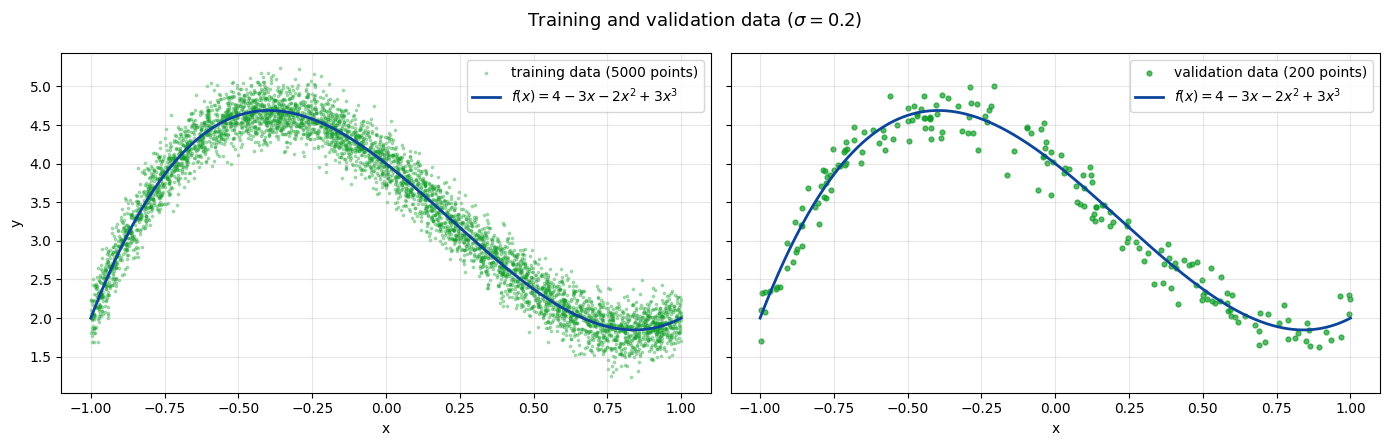

In [19]:
np.random.seed(0)

N_train, N_valid = 5000, 200
sigma = 0.2

x_train = np.random.uniform(-1, 1, N_train)
x_valid = np.sort(np.random.uniform(-1, 1, N_valid))
y_train = np.random.normal(cubic_function(x_train), sigma)
y_valid = np.random.normal(cubic_function(x_valid), sigma)

x_plot = np.linspace(-1, 1, 400)

fig, axs = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
axs[0].scatter(x_train, y_train, s=3, color=C_GREEN, alpha=0.3, label=f'training data ({N_train} points)')
axs[1].scatter(x_valid, y_valid, s=12, color=C_GREEN, alpha=0.7, label=f'validation data ({N_valid} points)')
for ax in axs:
    ax.plot(x_plot, cubic_function(x_plot), color=C_BLUE, lw=2, label=r'$f(x) = 4 - 3x - 2x^2 + 3x^3$')
    ax.set(xlabel='x')
    ax.legend()
    ax.grid(True, alpha=0.3)
axs[0].set_ylabel('y')
fig.suptitle(rf'Training and validation data ($\sigma = {sigma}$)', fontsize=13)
plt.tight_layout()
plt.show()

#### Grid search

To compute the grid search we implemented the function <small><code>train_model</code></small> which builds a network with the given architecture, trains it, and returns the model, its training history, and its MSE with respect to the exact function inside and outside the training interval. The random seed of TensorFlow is fixed, so that all models of the grid start from comparable conditions and the search is reproducible. For each model we stored the validation MSE (the same metric for all models, whatever the loss used in training) and the two errors with respect to $f(x)$.

In [ ]:
x_in  = np.linspace(-1, 1, 400) # inside the training range
x_out = np.concatenate([np.linspace(-1.5, -1, 100), np.linspace(1, 1.5, 100)]) # outside

def train_model(n_layers, n_neurons, activation, optimizer, loss, seed=0, epochs=50):
    tf.keras.backend.clear_session()
    tf.random.set_seed(seed)
    model = tf.keras.Sequential([Input(shape=(1,))])
    for _ in range(n_layers):
        model.add(Dense(n_neurons, activation=activation))
    model.add(Dense(1))
    model.compile(optimizer=optimizer, loss=loss, metrics=['mse'])
    history = model.fit(x_train, y_train, epochs=epochs, batch_size=32,
                        validation_data=(x_valid, y_valid), verbose=0)
    # error with respect to the exact function
    mse_in  = np.mean((model.predict(x_in,  verbose=0).ravel() - cubic_function(x_in))**2)
    mse_out = np.mean((model.predict(x_out, verbose=0).ravel() - cubic_function(x_out))**2)
    return model, history.history, mse_in, mse_out

results = []
for n_layers, n_neurons, activation, optimizer, loss in tqdm(combinations, desc="Grid search"):
    _, h, mse_in, mse_out = train_model(n_layers, n_neurons, activation, optimizer, loss)
    results.append({'layers': n_layers, 'neurons': n_neurons, 'activation': activation,
                    'optimizer': optimizer, 'loss': loss,
                    'val_mse': h['val_mse'][-1], 'mse_true_in': mse_in, 'mse_true_out': mse_out})

Grid search: 100%|██████████| 216/216 [1:16:38<00:00, 21.29s/it]


In [21]:
import pandas as pd
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D

C_BLUE, C_GREEN, C_LIGHTGREEN = "#0c459a", "#109e28", "#8fd19e"
PALETTE = ['#0b6e1f', '#109e28', '#5cc46a', '#b7e4b9', '#eef3f8', '#9dbbe6', '#4a7fcc', '#0c459a']

df = pd.DataFrame(results)
df['params'] = 2*df.neurons + (df.layers - 1)*(df.neurons**2 + df.neurons) + df.neurons + 1
df['name'] = (df.layers.astype(str) + 'x' + df.neurons.astype(str) + ' ' + df.activation
              + ' | ' + df.optimizer + ' | ' + df.loss)

N_CAND = 5
candidates = df.nsmallest(N_CAND, "mse_true_in").copy()
df['candidate'] = df.index.isin(candidates.index)

pd.set_option('display.width', 150)
print('10 best models by error with respect to the exact function, inside [-1, 1]:')
print(df.nsmallest(10, 'mse_true_in')[['name', 'params', 'val_mse', 'mse_true_in', 'mse_true_out']]
      .to_string(index=False, float_format='%.5f'))

10 best models by error with respect to the exact function, inside [-1, 1]:
                     name  params  val_mse  mse_true_in  mse_true_out
   3x32 relu | adam | mse    2209  0.04107      0.00046       8.82341
   3x32 tanh | adam | mae    2209  0.04165      0.00081       4.03348
    3x8 relu | adam | mse     169  0.04248      0.00102       8.52456
    3x8 relu | adam | mae     169  0.04164      0.00114       8.33784
   2x16 relu | adam | mse     321  0.04259      0.00117       7.79458
3x16 tanh | rmsprop | mae     593  0.04291      0.00134       6.04475
   2x32 relu | adam | mse    1153  0.04357      0.00136      10.00871
   3x16 tanh | adam | mse     593  0.04285      0.00136       5.33967
   2x16 tanh | adam | mae     321  0.04097      0.00149       5.28345
    2x8 tanh | adam | mae      97  0.04149      0.00154       5.13351


The table lists the 10 best models according to the error with respect to $f(x)$ inside $[-1,1]$. Their validation MSE is very close to $\sigma^2 = 0.04$ for all of them, so the validation loss alone could not distinguish them, and it would even give a different ranking. The error with respect to the exact function, instead, clearly separates the models.

All these models are much better than the noise level: the best one deviates from the true function by only about $0.0005$, tre magnitude orders less than $\sigma = 0.2$, because the network averages over thousands of noisy points. Almost all of them are trained with Adam and use ReLU or tanh, while the training loss (MSE or MAE) does not seem to matter. Outside the training interval, instead, the error is very large for all of them: none of these networks is able to extrapolate the cubic.

The code below draws a heat map that compares the error of all the studied models. Each cell is one model: the rows give the number of layers and the activation, the columns the optimizer and the number of neurons, and the two panels correspond to the two losses used in the training.

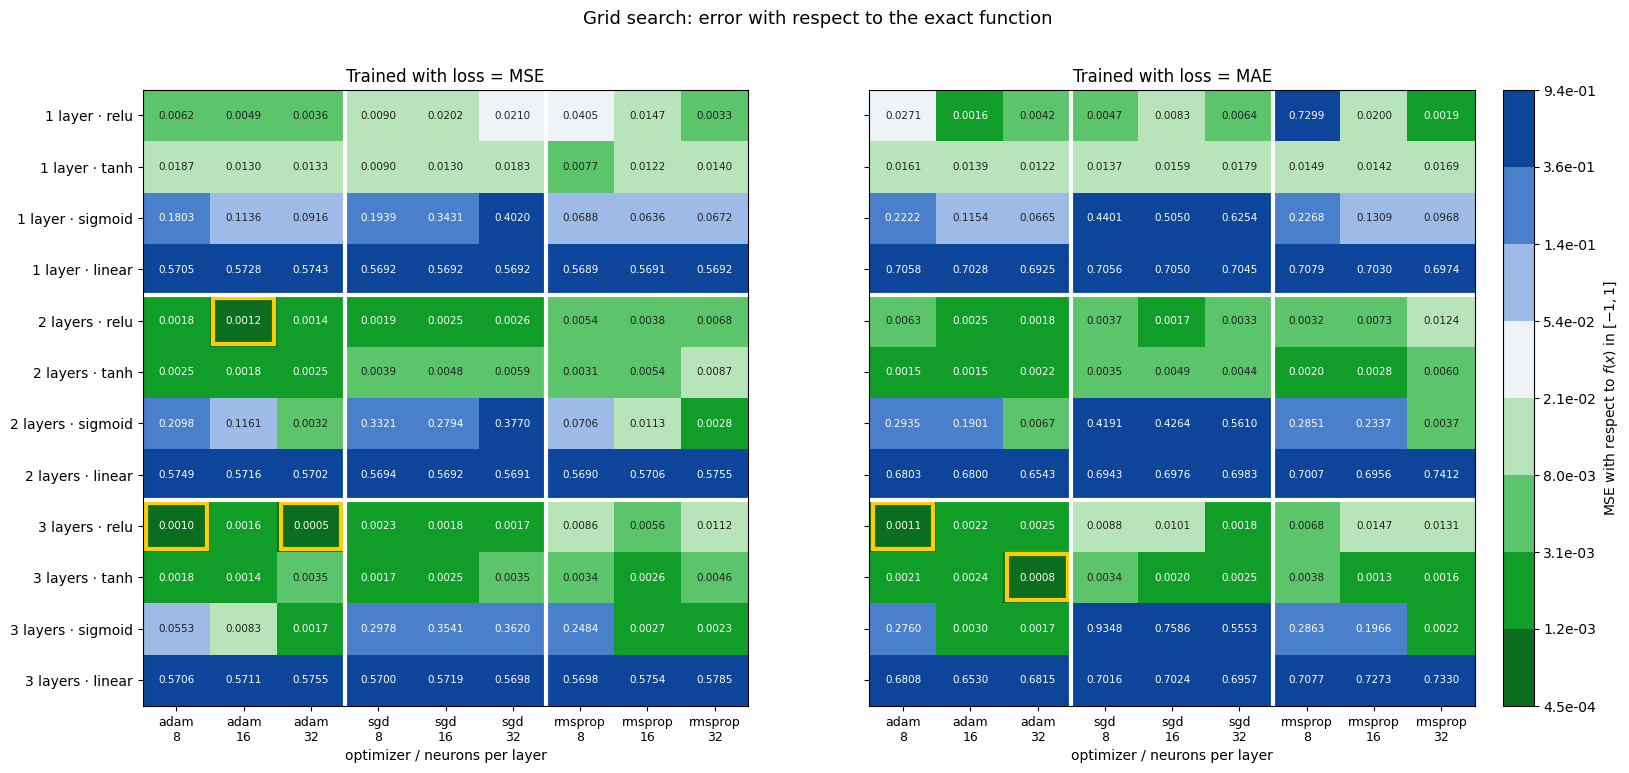

In [22]:
rows = [(l, a) for l in layer_options for a in activation_options]
cols = [(o, n) for o in optimizer_options for n in neurons_options]
edges = np.geomspace(df.mse_true_in.min() * 0.99, df.mse_true_in.max() * 1.01, len(PALETTE) + 1)
cmap, norm = ListedColormap(PALETTE), BoundaryNorm(edges, len(PALETTE))
dark = {0, 1, len(PALETTE) - 2, len(PALETTE) - 1}            # classes with white text

fig, axs = plt.subplots(1, len(loss_options), figsize=(18, 8), sharey=True)
for ax, lo in zip(axs, loss_options):
    sub = df[df.loss == lo].set_index(['layers', 'activation', 'optimizer', 'neurons'])
    M = np.array([[sub.loc[(l, a, o, n), 'mse_true_in'] for (o, n) in cols] for (l, a) in rows])
    K = np.array([[sub.loc[(l, a, o, n), 'candidate'] for (o, n) in cols] for (l, a) in rows])
    im = ax.imshow(M, cmap=cmap, norm=norm, aspect='auto')
    for i in range(len(rows)):
        for j in range(len(cols)):
            ax.text(j, i, f'{M[i, j]:.4f}', ha='center', va='center', fontsize=7.5,
                    color='white' if int(norm(M[i, j])) in dark else '#222222')
            if K[i, j]:
                ax.add_patch(Rectangle((j - 0.45, i - 0.45), 0.9, 0.9, fill=False, ec='#ffcc00', lw=3))
    for k in range(1, len(layer_options)):
        ax.axhline(k * len(activation_options) - 0.5, color='white', lw=3)
    for k in range(1, len(optimizer_options)):
        ax.axvline(k * len(neurons_options) - 0.5, color='white', lw=3)
    ax.set_xticks(range(len(cols)), [f'{o}\n{n}' for o, n in cols], fontsize=9)
    ax.set_yticks(range(len(rows)), [f'{l} layer{"s" if l > 1 else ""} · {a}' for l, a in rows])
    ax.set_xlabel('optimizer / neurons per layer')
    ax.set_title(f'Trained with loss = {lo.upper()}')

cb = fig.colorbar(im, ax=axs, fraction=0.025, pad=0.02, spacing='uniform')
cb.set_ticks(edges, labels=[f'{e:.1e}' for e in edges])
cb.set_label(r'MSE with respect to $f(x)$ in $[-1,1]$')
fig.suptitle(f'Grid search: error with respect to the exact function', fontsize=13)
plt.show()

In this map the colour classes are logarithmic, from dark green (smallest error) to dark blue (largest), and the yellow frames mark the five best models, which are analysed further below.

The linear activation gives the same large error for every choice of layers, neurons and optimizer. This was expected as a composition of linear layers is still a linear function, so these networks can only find the best straight line through the cubic so this is a clear case of underfitting.

The sigmoid activation also gives large errors in most cases, especially with SGD. This could be because the sigmoid saturates easily, so the training is slow and in 50 epochs most of these networks have not converged yet. Some sigmoid networks that were trained with Adam or RMSprop still reach small errors, so the problem is the speed of the training, not the activation itself.

ReLU and tanh, on the other hand, fit the cubic well in almost all cases, and networks with 2 or 3 layers do better than those with a single layer. Among the optimizers, Adam gives the best results, RMSprop is close to it, and SGD is clearly worse, because with a fixed learning rate it converges more slowly. Finally, the training loss (MSE or MAE) makes little difference for the good models.

#### Choice of the model

In the grid search each model was trained only once. A single training run, however, depends on the random initial weights, so two models with similar errors could swap places if the training were repeated. To make the choice more robust, we trained the 5 best models again with 5 different random seeds, and for each of them we computed the mean and the standard deviation of the error with respect to $f(x)$. We then took the model with the smallest mean error; if other models had a mean error within one standard deviation of it, we would consider them equivalent and choose the one with the fewest parameters.

In the figure the nine architectures are ordered by their number of parameters. The light green bars show the smallest error obtained by each architecture in the grid search, and the points with error bars show the mean and standard deviation over the 5 seeds for the five candidates. The chosen model is shown in dark green.

In [23]:
SEEDS = [0, 1, 2, 3, 4]
runs = {}
for idx, c in candidates.iterrows():
    runs[idx] = [train_model(c.layers, c.neurons, c.activation, c.optimizer, c.loss, seed=s) for s in SEEDS]
    candidates.loc[idx, 'mean_in']  = np.mean([r[2] for r in runs[idx]])
    candidates.loc[idx, 'std_in']   = np.std([r[2] for r in runs[idx]])
    candidates.loc[idx, 'mean_out'] = np.mean([r[3] for r in runs[idx]])

best_c = candidates.loc[candidates.mean_in.idxmin()]
equivalent = candidates[candidates.mean_in <= best_c.mean_in + best_c.std_in]
chosen = equivalent.sort_values(['params', 'mean_in']).iloc[0]

print(candidates[['name', 'params', 'mean_in', 'std_in', 'mean_out']].to_string(index=False, float_format='%.5f'))
print(f'\nChosen model: {chosen["name"]} ({chosen.params} parameters)')

                  name  params  mean_in  std_in  mean_out
3x32 relu | adam | mse    2209  0.00256 0.00102   9.19615
3x32 tanh | adam | mae    2209  0.00312 0.00168   4.19703
 3x8 relu | adam | mse     169  0.00228 0.00102   9.02039
 3x8 relu | adam | mae     169  0.00318 0.00176   7.64647
2x16 relu | adam | mse     321  0.00121 0.00067   9.74129

Chosen model: 2x16 relu | adam | mse (321 parameters)


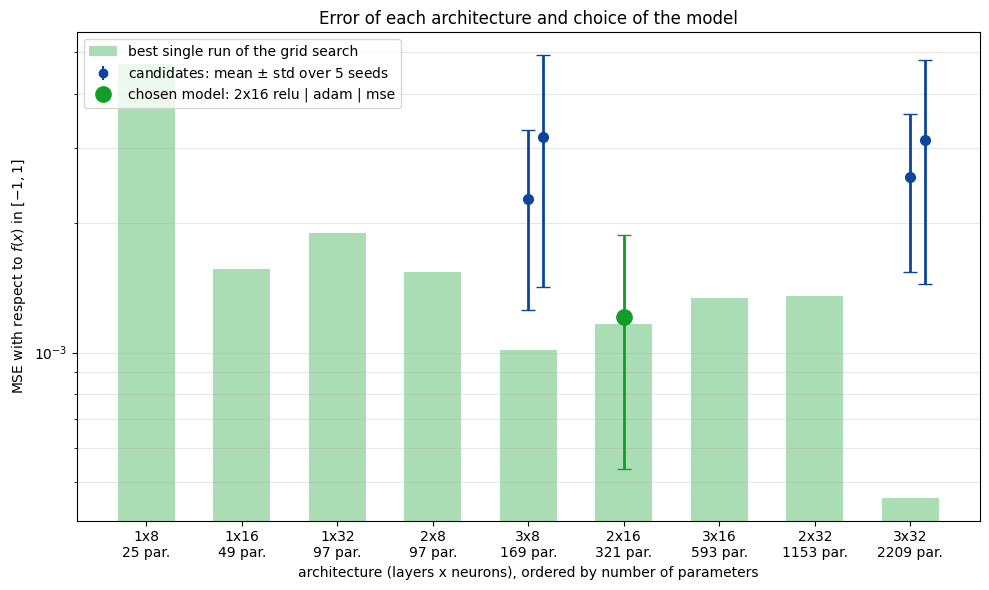

In [24]:
# best error of each architecture in the grid search
arch = (df.groupby(['layers', 'neurons'])
          .agg(params=('params', 'first'), best_in=('mse_true_in', 'min'))
          .reset_index().sort_values(['params', 'layers']).reset_index(drop=True))
pos = {(l, n): i for i, (l, n) in enumerate(zip(arch.layers, arch.neurons))}

fig, ax = plt.subplots(figsize=(10, 6))
ax.bar(arch.index, arch.best_in, color=C_GREEN, alpha=0.35, width=0.6,
       label='best single run of the grid search')


shift = {} # small horizontal shift if two candidates share an architecture
for idx, c in candidates.iterrows():
    is_chosen = (idx == chosen.name)
    k = shift.get((c.layers, c.neurons), 0)
    shift[(c.layers, c.neurons)] = k + 1
    ax.errorbar(pos[(c.layers, c.neurons)] + 0.15 * k, c.mean_in, yerr=c.std_in, fmt='o', capsize=5,
                ms=11 if is_chosen else 7, elinewidth=2,
                color=C_GREEN if is_chosen else C_BLUE)
ax.errorbar([], [], yerr=[], fmt='o', color=C_BLUE, label=f'candidates: mean $\\pm$ std over {len(SEEDS)} seeds')
ax.errorbar([], [], yerr=[], fmt='o', ms=11, color=C_GREEN, label=f'chosen model: {chosen["name"]}')

ax.set_xticks(arch.index, [f'{l}x{n}\n{p} par.' for l, n, p in zip(arch.layers, arch.neurons, arch.params)])
ax.set(yscale='log', xlabel='architecture (layers x neurons), ordered by number of parameters',
       ylabel=r'MSE with respect to $f(x)$ in $[-1,1]$',
       title='Error of each architecture and choice of the model')
ax.legend()
ax.grid(True, axis='y', which='both', alpha=0.3)
plt.tight_layout()
plt.show()

The bars show that, apart from the smallest network (one layer of 8 neurons), all architectures reach similar errors, without a clear trend with the number of parameters: beyond a few tens of parameters the network is already flexible enough to represent a cubic.

When the candidates are trained again with different seeds, most of them have a mean error clearly larger than their best run in the grid search, so those very small errors were partly due to a lucky initialisation. The network with 2 hidden layers of 16 ReLU neurons, trained with Adam and the MSE loss, behaves differently: its mean error is similar to its best run and is the smallest of the five, about half of the others. It is therefore the most reliable model, and it is also relatively simple, with 321 parameters.

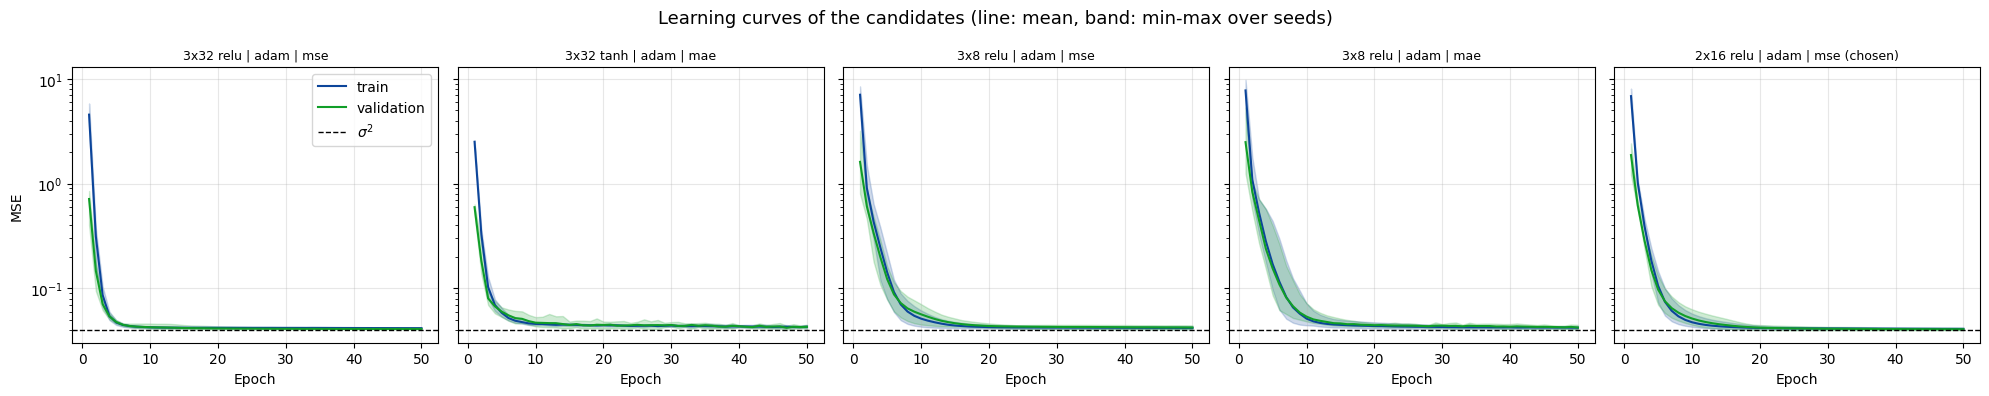

In [25]:
fig, axs = plt.subplots(1, len(candidates), figsize=(4 * len(candidates), 4), sharey=True)
for ax, (idx, c) in zip(axs, candidates.iterrows()):
    for key, col, lab in [('mse', C_BLUE, 'train'), ('val_mse', C_GREEN, 'validation')]:
        curves = np.array([r[1][key] for r in runs[idx]])
        ep = np.arange(1, curves.shape[1] + 1)
        ax.plot(ep, curves.mean(0), color=col, label=lab)
        ax.fill_between(ep, curves.min(0), curves.max(0), color=col, alpha=0.2)
    ax.axhline(sigma**2, color='k', ls='--', lw=1, label=r'$\sigma^2$')
    ax.set(yscale='log', xlabel='Epoch', title=c['name'] + (' (chosen)' if idx == chosen.name else ''))
    ax.title.set_fontsize(9)
    ax.grid(True, alpha=0.3)
axs[0].set_ylabel('MSE')
axs[0].legend()
fig.suptitle('Learning curves of the candidates (line: mean, band: min-max over seeds)', fontsize=13)
plt.tight_layout()
plt.show()

For a more complete analysis we also checked the learning curves of the five candidates. In all cases the training and validation losses decrease together and become flat at about $\sigma^2 = 0.04$ within the 50 epochs, and the validation loss never rises. The networks have therefore converged, and there is no sign of overfitting: with 5000 training points, even the largest network did not learn the noise of the data.

#### Predictions of the chosen model

Finally we tested the chosen model on new points in the interval $[-2,2]$, to see its behaviour both inside and outside the training range. The left plot shows the predicted function compared with the true one, and the right plot shows the training and validation loss.

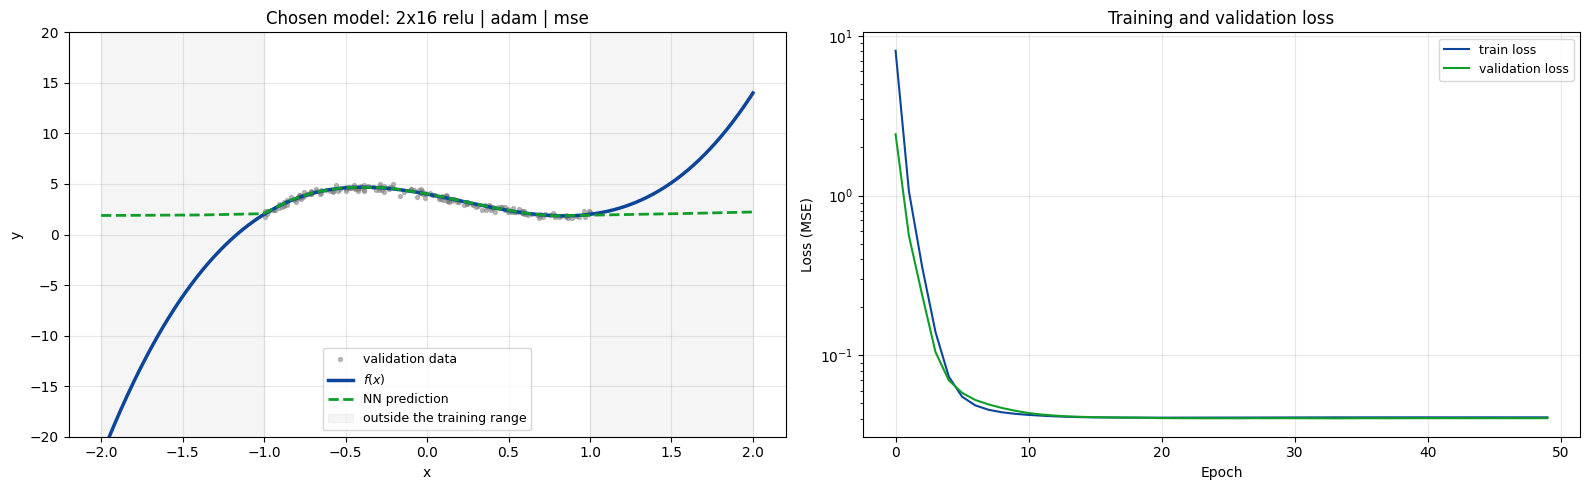

MSE vs f, |x| <= 1     : 5.55e-04
MSE vs f, 1 < |x| <= 2 : 8.22e+01


In [26]:
# chosen model, trained with the first seed
model_best, hist_best = runs[chosen.name][0][0], runs[chosen.name][0][1]

x_test = np.linspace(-2, 2, 800)
y_pred = model_best.predict(x_test, verbose=0).ravel()
inside = np.abs(x_test) <= 1

fig, axs = plt.subplots(1, 2, figsize=(16, 5))

# prediction vs target
ax = axs[0]
ax.scatter(x_valid, y_valid, s=8, color='grey', alpha=0.5, label='validation data')
ax.plot(x_test, cubic_function(x_test), color=C_BLUE, lw=2.5, label=r'$f(x)$')
ax.plot(x_test, y_pred, color=C_GREEN, lw=2, ls='--', label='NN prediction')
ax.axvspan(-2, -1, color='grey', alpha=0.08)
ax.axvspan(1, 2, color='grey', alpha=0.08, label='outside the training range')
ax.set(xlabel='x', ylabel='y', ylim=(-20, 20), title=f'Chosen model: {chosen["name"]}')

# training and validation loss
ax = axs[1]
ax.plot(hist_best['loss'], color=C_BLUE, label='train loss')
ax.plot(hist_best['val_loss'], color=C_GREEN, label='validation loss')
ax.set(xlabel='Epoch', ylabel=f'Loss ({chosen.loss.upper()})', yscale='log', title='Training and validation loss')

for a in axs:
    a.legend(fontsize=9)
    a.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f'MSE vs f, |x| <= 1     : {np.mean((y_pred[inside] - cubic_function(x_test[inside]))**2):.2e}')
print(f'MSE vs f, 1 < |x| <= 2 : {np.mean((y_pred[~inside] - cubic_function(x_test[~inside]))**2):.2e}')

Inside the training range $[-1,1]$ the prediction lies on top of the cubic and follows the validation points well, with a typical deviation from the true function of about $0.02$, much smaller than the noise.

Outside $[-1,1]$ the network fails completely, its prediction stays almost flat, while the cubic grows quickly. This was to be expected, because the network has no information on the function outside the region where it was trained.

The loss drops quickly in the first 10 epochs and then stays flat, with training and validation loss on top of each other, so the network has converged and there is no overfitting.

To sum up, a non-linear activation is necessary to fit the cubic, and a small network of a few hundred parameters (2 layers of 16 ReLU neurons, trained with Adam) is already enough, since bigger networks do not give a better fit. The chosen model predicts new data very well inside the training interval, but it cannot be used to extrapolate new data outside it.

### Exercise 11.3
  
Try to extend the model to fit a simple trigonometric 2D function such as $f(x,y) = \sin(x^2+y^2)$ in the range $x \in [-3/2,3/2]$ and $y \in [-3/2,3/2]$.

Ideas to meditate on these exercises and judge your results can be found <a href=https://xkcd.com/2048/>here</a>

### <span style="color:green"> RESULTS: </span>

In this exercise we implemented a neural network able to perform a regression in two dimensions. The network has to learn $f(x,y) = \sin(x^2+y^2)$ on the square $[-3/2,3/2]^2$ from training data $z_i = f(x_i,y_i)+\eta_i$, with Gaussian noise with $\sigma = 0.2$ as before.

Compared with the one-dimensional case the input now has two coordinates, hence the input layer should be <small><code>Input(shape=(2,))</code></small> and the training inputs should come form an array of shape $(N_{\rm train}, 2)$. For this reason more training data are needed, since they have to cover a two-dimensional domain, so we used $N_{\rm train}=10^4$ training points and $N_{\rm valid}=10^3$ validation points, uniformly distributed in the square.

The target function is $\sin r^2$ with $r^2 = x^2+y^2$ and its graph is a set of concentric rings, which become narrower towards the corners of the square, where $r^2$ reaches $4.5$. As in 11.2, we use hidden layers with the <small><code>tanh</code></small> activation, which gives smooth functions like the target, and a linear output neuron, we then trained with the Adam optimizer and the MSE loss, using minibatches of 32 points for 100 epochs.

In [27]:
from matplotlib.colors import LinearSegmentedColormap

C_BLUE, C_GREEN = "#0c459a", "#109e28"
CMAP_F   = LinearSegmentedColormap.from_list('blue_white_green', [C_BLUE, '#f7f7f7', C_GREEN])   # values of f
CMAP_ERR = LinearSegmentedColormap.from_list('white_blue', ['#ffffff', C_BLUE])                  # errors

# system parameters
N_train = 10000
N_valid = 1000
N_epochs = 100
sigma = 0.2
L = 1.5                  # training square [-L, L]^2

def f(x, y):
    return np.sin(x**2 + y**2)

In the plots below we show the true function together with the training data and the validation data.

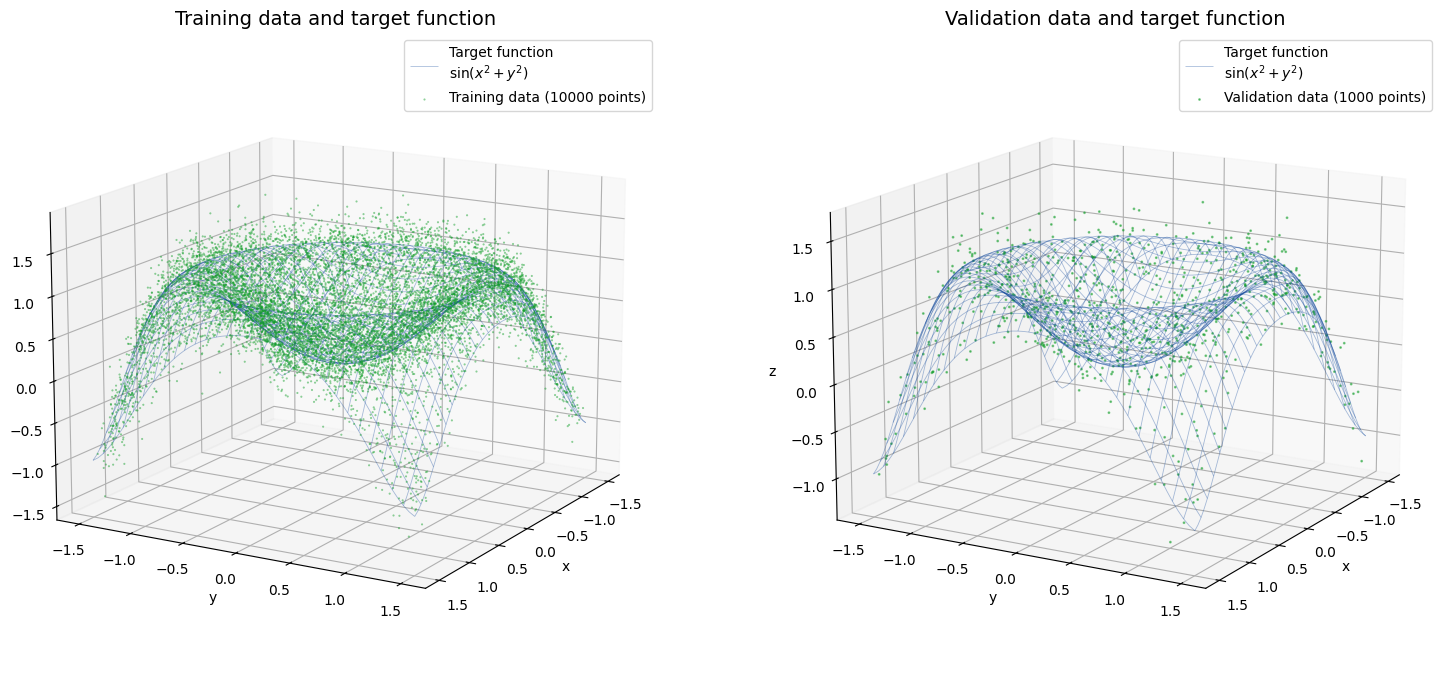

In [28]:
np.random.seed(0)
tf.random.set_seed(0)

# training and validation data, uniform in the square [-L, L]^2
XY_train = np.random.uniform(-L, L, (N_train, 2))
XY_valid = np.random.uniform(-L, L, (N_valid, 2))
z_train = np.random.normal(f(XY_train[:, 0], XY_train[:, 1]), sigma)
z_valid = np.random.normal(f(XY_valid[:, 0], XY_valid[:, 1]), sigma)

# grid for the plots
x_surf = np.linspace(-L, L, 61)
X_surf, Y_surf = np.meshgrid(x_surf, x_surf)

fig = plt.figure(figsize=(16, 7))
for k, (XY, z, name, size) in enumerate([(XY_train, z_train, 'Training data', 1),
                                         (XY_valid, z_valid, 'Validation data', 4)]):
    ax = fig.add_subplot(1, 2, k + 1, projection='3d')
    ax.plot_wireframe(X_surf, Y_surf, f(X_surf, Y_surf), color=C_BLUE, alpha=0.35, lw=0.6,
                      label='Target function\n' + r'$\sin(x^2+y^2)$')
    ax.scatter(XY[:, 0], XY[:, 1], z, marker='.', s=size, color=C_GREEN, alpha=0.5,
               label=f'{name} ({len(z)} points)')
    ax.set(xlabel='x', ylabel='y', zlabel='z')
    ax.set_title(f'{name} and target function', fontsize=14)
    ax.legend()
    ax.view_init(15, 30)
plt.tight_layout()
plt.show()

In [29]:
model_2d = tf.keras.Sequential([Input(shape=(2,)),
                                Dense(64, activation='tanh'),
                                Dense(64, activation='tanh'),
                                Dense(1)])
model_2d.compile(optimizer='adam', loss='mse', metrics=['mse'])
model_2d.summary()

history_2d = model_2d.fit(XY_train, z_train, epochs=N_epochs, batch_size=32, validation_data=(XY_valid, z_valid), verbose=0)

# error with respect to the exact function, on a dense grid inside and outside the training square
g = np.linspace(-2, 2, 201)
XX, YY = np.meshgrid(g, g)
Z_true = f(XX, YY)
Z_pred = model_2d.predict(np.column_stack([XX.ravel(), YY.ravel()]), verbose=0).reshape(XX.shape)
inside = (np.abs(XX) <= L) & (np.abs(YY) <= L)

print(f"Final validation MSE        : {history_2d.history['val_mse'][-1]:.4f}   (sigma^2 = {sigma**2:.4f})")
print(f"MSE vs f inside  [-1.5,1.5]^2 : {np.mean((Z_pred - Z_true)[inside]**2):.2e}")
print(f"MSE vs f outside [-1.5,1.5]^2 : {np.mean((Z_pred - Z_true)[~inside]**2):.2e}")

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 64)             │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,417 (17.25 KB)

 Trainable params: 4,417 (17.25 KB)

 Non-trainable params: 0 (0.00 B)

Final validation MSE        : 0.0391   (sigma^2 = 0.0400)
MSE vs f inside  [-1.5,1.5]^2 : 7.44e-04
MSE vs f outside [-1.5,1.5]^2 : 6.60e-01


After the training we compared the prediction of the network with the true function. We plotted the predictions of the network on a grid of points together with the target surface, and on the right the training and validation loss as a function of the epoch.

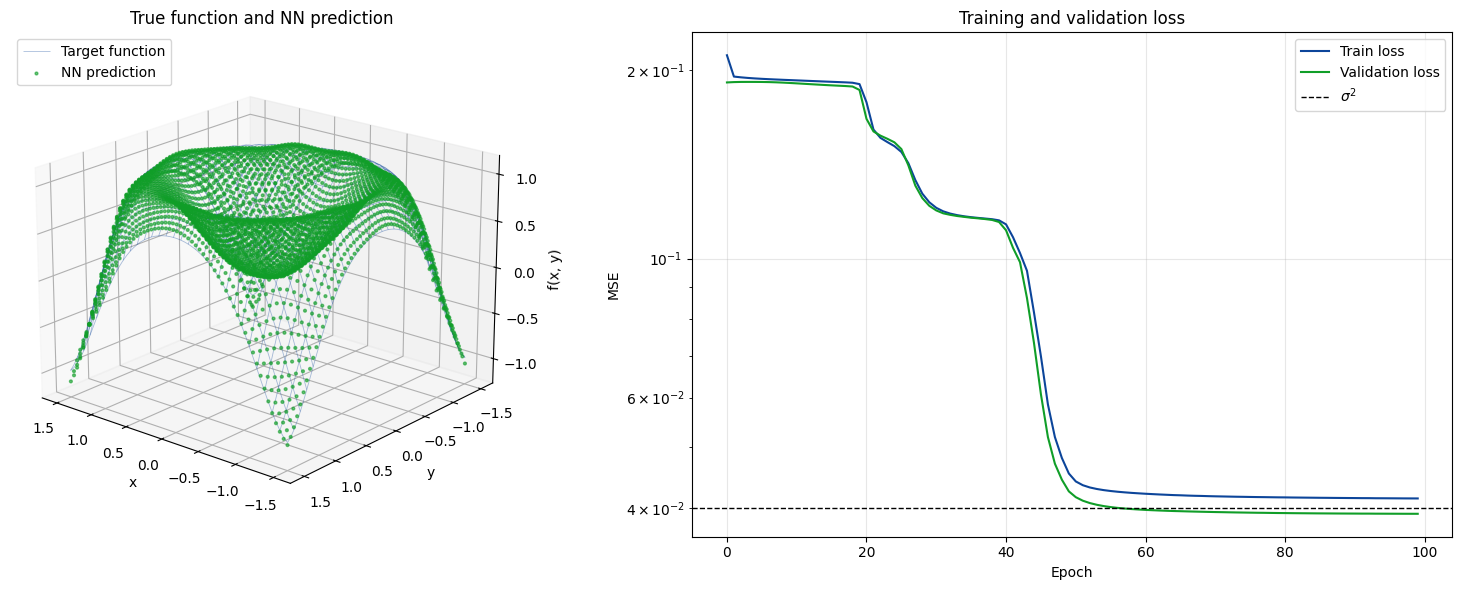

In [30]:
Z_pred_surf = model_2d.predict(np.column_stack([X_surf.ravel(), Y_surf.ravel()]), verbose=0).reshape(X_surf.shape)

fig = plt.figure(figsize=(16, 6))
ax1 = fig.add_subplot(1, 2, 1, projection='3d')
ax1.plot_wireframe(X_surf, Y_surf, f(X_surf, Y_surf), color=C_BLUE, alpha=0.35, lw=0.6, label='Target function')
ax1.scatter(X_surf.ravel(), Y_surf.ravel(), Z_pred_surf.ravel(), s=4, color=C_GREEN, alpha=0.6,label='NN prediction')
ax1.set(xlabel='x', ylabel='y', zlabel='f(x, y)', title='True function and NN prediction')
ax1.legend(loc='upper left')
ax1.view_init(elev=20, azim=130)

ax2 = fig.add_subplot(1, 2, 2)
ax2.plot(history_2d.history['loss'], color=C_BLUE, label='Train loss')
ax2.plot(history_2d.history['val_loss'], color=C_GREEN, label='Validation loss')
ax2.axhline(sigma**2, color='k', ls='--', lw=1, label=r'$\sigma^2$')
ax2.set(yscale='log', xlabel='Epoch', ylabel='MSE', title='Training and validation loss')
ax2.legend(loc='upper right')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

The predicted points follow the target surface in the whole training square.

The loss graph shows an interesting behaviour, in the first 20 epochs the loss stays almost constant, just below $0.2$; at this stage the network predicts more or less the same value everywhere, close to the mean of the data, so it has only learned the average height of the surface. After that the loss decreases in steps, while the network gradually learns the shape of the rings, and after about 50 epochs it becomes flat, close to $\sigma^2 = 0.04$. Then training and validation loss stay close until the end, so there is no overfitting.

#### Conclusions

The network reproduces the function $\sin(x^2+y^2)$ very well inside the training square, with an error with respect to the exact function much smaller than the noise $\sigma = 0.2$ on the data.

Compared with the one-dimensional case, the problem is more expensive: to cover a two-dimensional domain we needed $10^4$ training points and a larger network, with about 4400 parameters instead of a few hundred, and the training took more epochs to converge. Apart from this, the same kind of network used in 11.2 works well also for a function of two variables.